# Process the sqY2H data

This is the main PPI profiling assay. This script loads the raw scores and processes them into consensus scores. Throughout the script, "ad" means "activation domain" and "db" means "DNA binding domain" of a transcription factor. A protein is fused to each of these; if the two proteins interact, then the TF is able to up-regulate the expression of a gene that allows the yeast to survive on the media. Thus, the yeast growth score is correlated to the protein-protein interaction strength.

In [1]:
import pandas as pd 
import polars as pl
import numpy as np
from striprtf.striprtf import rtf_to_text
import re

In [2]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs"
meta_outputs = "../../../1_allele_collection/3_outputs"
meta_inputs = "../../../1_allele_collection/1_inputs"

# Automated clean processing

In [3]:
auto_df = pd.read_csv(f"{inputs_dir}/sqY2H_manual_automated_annotated_scores.csv")
auto_df = auto_df[
    (~auto_df.ad_orf_id.isin(['nan', 'None'])) &
    (~auto_df.db_orf_id.isin(['nan', 'None']))
]

auto_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,A01_1,NaN,DB_hap_ctrl,A10,AD_hap_ctrl,A10,4.0,490.572572
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,A01_1,NaN,DB_hap_ctrl,A10,AD_hap_ctrl,A10,4.0,521.929437
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,2651.0,0.0,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,455.656230
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,2651.0,0.0,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,544.304600
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,7215.0,0.0,DisWTGDEh03,E01,CEGSint_Y8A1_2_6,A01,4.0,505.925513
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,54308.0,218854.0,VUSMutY8Dh022,H09,CEGSint_Y8A_6,E11,2.0,435.596088
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,54308.0,218855.0,VUSMutY8Dh022,B10,CEGSint_Y8A_6,E11,2.0,811.030089
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,54308.0,218855.0,VUSMutY8Dh022,B10,CEGSint_Y8A_6,E11,2.0,830.430091
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.239216


In [4]:
auto_df.retest_batch.unique()

array(['VUSAPWT1B1', nan, 'VUSAPWT1B2', 'VUSAPWT2B1', 'VUSAPWT6B1'],
      dtype=object)

In [5]:
# Identify weird duplicates coming from the automated pipeline

auto_df[auto_df.duplicated(subset=['scoring_pla', 'scoring_pos', 'large_plate_name', 'retest_batch',
       'condition', 'condition_name', 'assay_id', 'media_control', 'ad_orf_id',
       'ad_mut_id', 'db_orf_id', 'db_mut_id', 'db_source_plate',
       'db_source_well', 'ad_source_plate', 'ad_source_well',
        'manual_score_growth'])]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray
138285,VUSAPWT1B2r06_010,A01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,10057.0,NaN,3980.0,0.0,DisWTY8Dh03,G09,CEGSint_Y8A_6,G11,0.0,125.037911
138334,VUSAPWT1B2r06_010,B01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,10057.0,NaN,3980.0,0.0,DisWTY8Dh03,G09,CEGSint_Y8A_6,G11,0.0,0.000000
138382,VUSAPWT1B2r06_010,C01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,0.0,NaN,7463.0,0.0,DisWTY8Dh03,H09,CEGSint_Y8A1_2_6,B01,0.0,0.000000
138430,VUSAPWT1B2r06_010,D01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,0.0,NaN,7463.0,0.0,DisWTY8Dh03,H09,CEGSint_Y8A1_2_6,B01,0.0,0.000000
138478,VUSAPWT1B2r06_010,E01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,100010020.0,NaN,7463.0,0.0,DisWTY8Dh03,H09,CEGSint_Y8A_1,G01,NaN,0.000000
138526,VUSAPWT1B2r06_010,F01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,100010020.0,NaN,7463.0,0.0,DisWTY8Dh03,H09,CEGSint_Y8A_1,G01,NaN,0.000000
138574,VUSAPWT1B2r06_010,G01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,978.0,NaN,7463.0,0.0,DisWTY8Dh03,H09,CEGSint_Y8A_4,E06,2.0,0.000000
138622,VUSAPWT1B2r06_010,H01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,978.0,NaN,7463.0,0.0,DisWTY8Dh03,H09,CEGSint_Y8A_4,E06,2.0,0.000000
138670,VUSAPWT1B2r06_010,I01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,0.0,NaN,3844.0,0.0,DisWTY8Dh03,A10,CEGSint_Y8A1_2_6,B01,0.0,0.000000
138718,VUSAPWT1B2r06_010,J01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,0.0,NaN,3844.0,0.0,DisWTY8Dh03,A10,CEGSint_Y8A1_2_6,B01,0.0,0.000000


In [6]:
auto_df.drop_duplicates(subset=['scoring_pla', 'scoring_pos', 'large_plate_name', 'retest_batch',
       'condition', 'condition_name', 'assay_id', 'media_control', 'ad_orf_id',
       'ad_mut_id', 'db_orf_id', 'db_mut_id', 'db_source_plate',
       'db_source_well', 'ad_source_plate', 'ad_source_well',
        'manual_score_growth'], keep='first', inplace=True)

In [7]:
auto_df.to_csv(f"{outputs_dir}/sqY2H/sqY2H_raw_scores_manual_automated.csv", index=False)

Number of rows before replacing outliers: 306431
Number of values replaced with NaN: 3057
Percentage of values replaced: 1.00%
Number of rows after replacing outliers: 306431


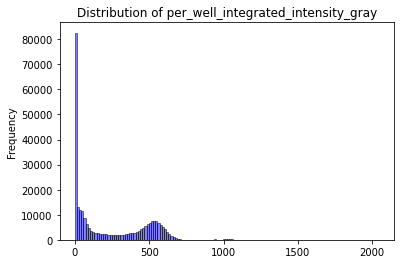

In [8]:
# Load the data from the automated scoring pipeline
auto_df = pd.read_csv(f"{inputs_dir}/sqY2H_manual_automated_annotated_scores.csv")

# both ad_orf_id and db_orf_id must have values (otherwise they are empty wells)
auto_df = auto_df[
    (~auto_df.ad_orf_id.isin(['nan', 'None'])) &
    (~auto_df.db_orf_id.isin(['nan', 'None']))
]

# Remove rows where manual_score_growth is NaN because those wells are flagged as contamination

# do not drop but replace the automatic scores by NA or just add a column for the failling of the manual annotation
# auto_df.dropna(subset=['manual_score_growth'], inplace=True)
auto_df['contamination'] = auto_df['manual_score_growth'].isna()
auto_df

# try to replace per_well_integrated_intensity_gray with NaN if manual_score_growth is NaN
auto_df.loc[auto_df['manual_score_growth'].isna(), 'per_well_integrated_intensity_gray'] = np.nan

# plotting the distribution of per_well_integrated_intensity_gray
auto_df.per_well_integrated_intensity_gray.plot(kind='hist', bins=140, alpha=0.5, color='blue', edgecolor='black', title="Distribution of per_well_integrated_intensity_gray")

# replacing upper bound outliers with NaN because they're caused by misaligned wells
auto_full = auto_df.copy()

# Counting the number of values replaced with NaN
outlier_mask = auto_df.per_well_integrated_intensity_gray >= 750
num_outliers = outlier_mask.sum()

print(f"Number of rows before replacing outliers: {len(auto_df)}")
auto_df.loc[outlier_mask, 'per_well_integrated_intensity_gray'] = np.nan
print(f"Number of values replaced with NaN: {num_outliers}")
print(f"Percentage of values replaced: {(num_outliers / len(auto_df)) * 100:.2f}%")
print(f"Number of rows after replacing outliers: {len(auto_df)}")

<Axes: title={'center': 'Distribution of per_well_integrated_intensity_gray'}, ylabel='Frequency'>

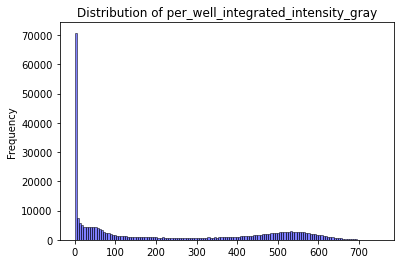

In [9]:
auto_df.per_well_integrated_intensity_gray.plot(kind='hist', bins=140, alpha=0.5, color='blue', edgecolor='black', title="Distribution of per_well_integrated_intensity_gray")


In [10]:
auto_df['automated_log2'] = np.log2(auto_df['per_well_integrated_intensity_gray'] + 50)  # Adding 1 to avoid log(0)

<Axes: title={'center': 'Distribution of log2(per_well_integrated_intensity_gray + 1)'}, ylabel='Frequency'>

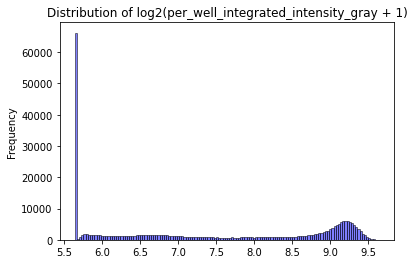

In [11]:
auto_df.automated_log2.plot(kind='hist', bins=140, alpha=0.5, color='blue', edgecolor='black', title="Distribution of log2(per_well_integrated_intensity_gray + 1)")

In [12]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

# Split into media controls
media_ctrls = auto_df[auto_df['media_control'] == True]
# auto_df = auto_df[~auto_df['media_control']]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'per_well_integrated_intensity_gray']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls

,db_orf_id,condition_name,retest_batch,per_well_integrated_intensity_gray,scoring_pos,retest_pla,control_384,lower_bound,upper_bound
0,A01_1,LW,VUSAPWT1B1,490.572572,A01,1,A01_A02_B01_B02,4,4
1,A01_1,LW,VUSAPWT1B1,521.929437,A01,1,A01_A02_B01_B02,4,4
2,A01_1,LW,VUSAPWT1B1,549.292837,A01,1,A01_A02_B01_B02,4,4
3,A01_1,LW,VUSAPWT1B1,477.786949,A01,1,A01_A02_B01_B02,4,4
4,B01_1,LW,VUSAPWT1B1,465.789564,B01,1,C01_C02_D01_D02,4,4
...,...,...,...,...,...,...,...,...,...
2392,E01_31,LWH25,VUSAPWT1B1,528.958176,E01,31,I01_I02_J01_J02,3,4
2393,F01_31,LWH25,VUSAPWT1B1,473.044449,F01,31,K01_K02_L01_L02,1,3
2394,F01_31,LWH25,VUSAPWT1B1,223.918957,F01,31,K01_K02_L01_L02,1,3
2395,F01_31,LWH25,VUSAPWT1B1,488.665364,F01,31,K01_K02_L01_L02,1,3


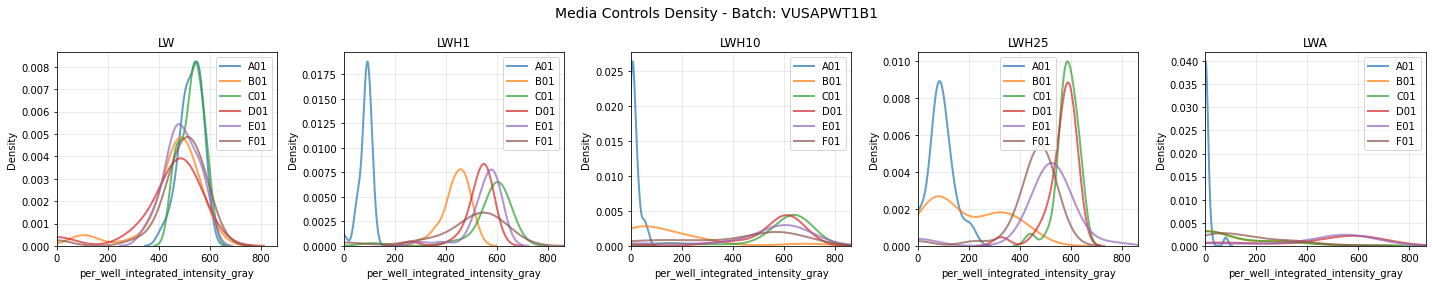

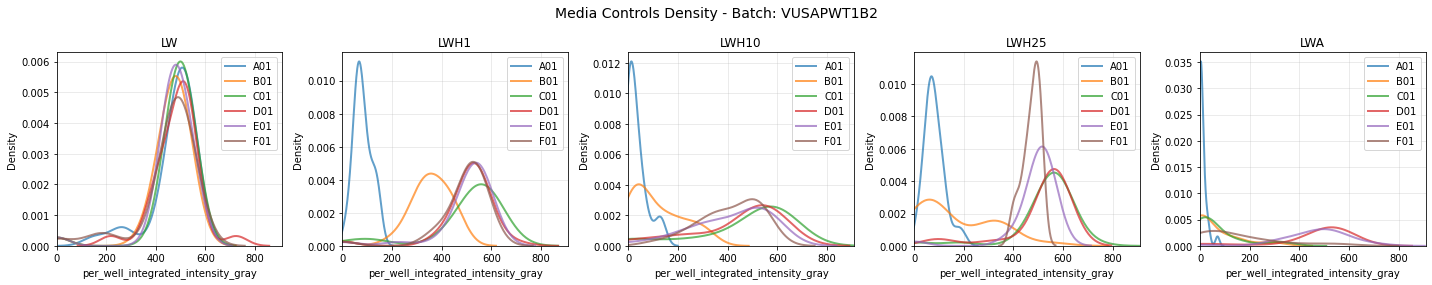

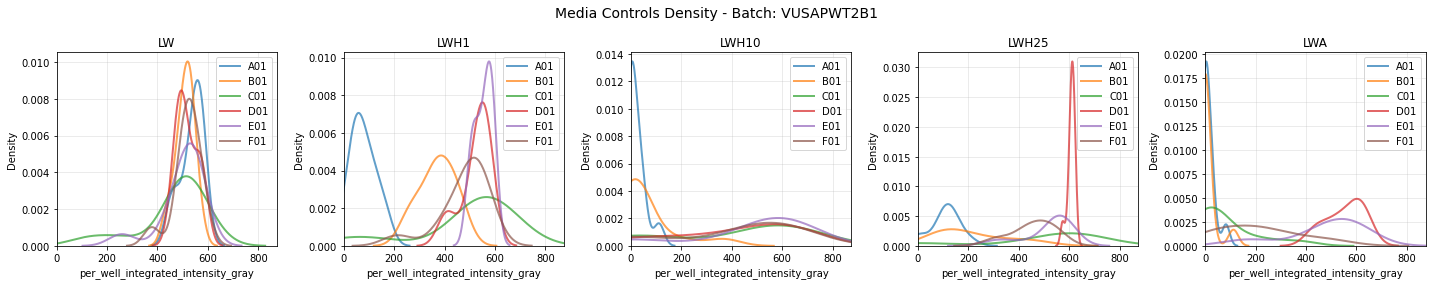

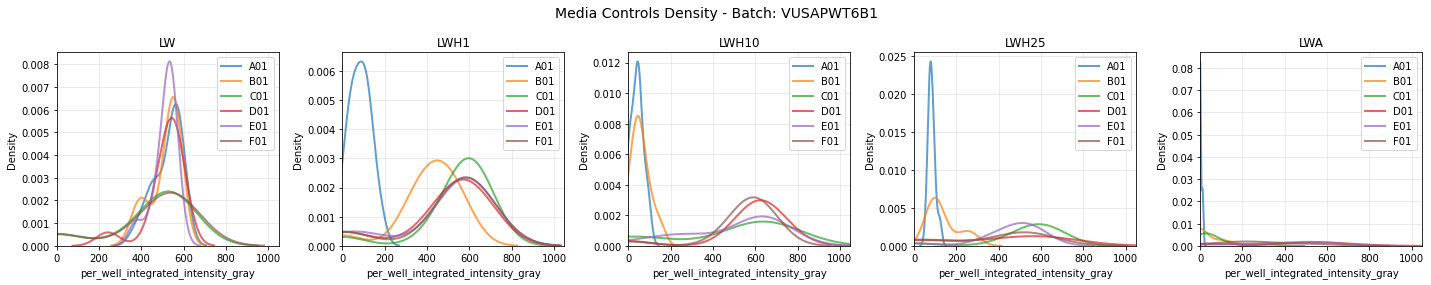

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get unique retest_batches and condition_names
retest_batches = media_ctrls['retest_batch'].unique()
condition_names = media_ctrls['condition_name'].unique()
condition_names = ['LW', 'LWH1', 'LWH10', 'LWH25', 'LWA']

for batch in retest_batches:
    # Filter data for this batch
    batch_data = media_ctrls[media_ctrls['retest_batch'] == batch]
    
    # Create subplots - one for each condition
    n_conditions = len(condition_names)
    fig, axes = plt.subplots(1, n_conditions, figsize=(4*n_conditions, 4), sharex=True)
    
    # Handle case where there's only one condition
    if n_conditions == 1:
        axes = [axes]
    
    fig.suptitle(f'Media Controls Density - Batch: {batch}', fontsize=14)
    
    for i, condition in enumerate(condition_names):
        ax = axes[i]
        condition_data = batch_data[batch_data['condition_name'] == condition]
        
        if len(condition_data) > 0:
            # Get unique scoring_pos for this condition
            scoring_positions = condition_data['scoring_pos'].unique()
            
            for pos in scoring_positions:
                pos_data = condition_data[condition_data['scoring_pos'] == pos]
                values = pos_data['per_well_integrated_intensity_gray'].values
                
                if len(values) > 0:
                    # Create density curve using seaborn kdeplot
                    sns.kdeplot(x=values, label=f'{pos}', alpha=0.7, linewidth=2, ax=ax)
        
        ax.set_title(f'{condition}')
        ax.set_xlabel('per_well_integrated_intensity_gray')
        ax.set_ylabel('Density')
        ax.set_xlim(left=0)  # Set lower bound of x-axis to 0
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

Condition: LW, Position: A01, Mean Intensity: 508.47624332414415
Condition: LW, Position: B01, Mean Intensity: 473.82834783764554
Condition: LW, Position: C01, Mean Intensity: 487.99298960678277
Condition: LW, Position: D01, Mean Intensity: 478.39780831933024
Condition: LWH1, Position: A01, Mean Intensity: 82.1676316505589
Condition: LWH1, Position: B01, Mean Intensity: 393.04126611985265
Condition: LWH1, Position: C01, Mean Intensity: 528.7809864666312
Condition: LWH1, Position: D01, Mean Intensity: 511.4863434772939
Condition: LWH10, Position: A01, Mean Intensity: 26.30607881033211
Condition: LWH10, Position: B01, Mean Intensity: 108.4384332422167
Condition: LWH10, Position: C01, Mean Intensity: 498.93467788379405
Condition: LWH10, Position: D01, Mean Intensity: 495.6099063884467
Condition: LWH25, Position: A01, Mean Intensity: 88.54923331032623
Condition: LWH25, Position: B01, Mean Intensity: 178.55600492472914
Condition: LWH25, Position: C01, Mean Intensity: 543.2821600682756
Condi

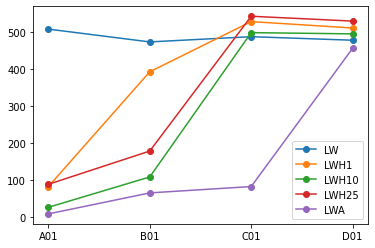

In [14]:
b_gal_scale = [0, 0.5, 100, 3000]

control_pos = ['A01', 'B01', 'C01', 'D01']

media_ctrls_1_to_4 = media_ctrls[media_ctrls.scoring_pos.isin(control_pos)]


for condition in condition_names:
    df = media_ctrls_1_to_4[media_ctrls_1_to_4.condition_name == condition]
    
    intensities = []
    
    for pos in control_pos:
        df_pos = df[df.scoring_pos == pos]
        mean_intensity = df_pos.per_well_integrated_intensity_gray.mean()
        intensities.append(mean_intensity)
        print(f'Condition: {condition}, Position: {pos}, Mean Intensity: {mean_intensity}')
        
    plt.plot(control_pos, intensities, marker='o', label=condition)
    # plt.scatter(b_gal_scale, intensities, label=condition)
    plt.legend()
    # plt.show()


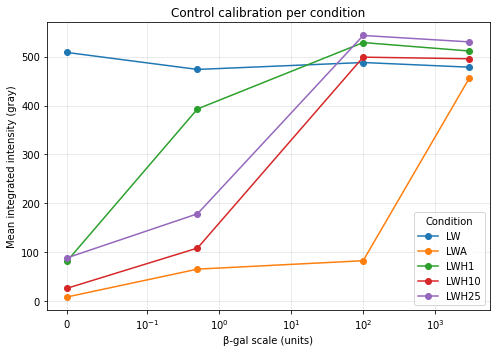

In [15]:
import numpy as np
import matplotlib.pyplot as plt

b_gal_scale = [0, 0.5, 100, 3000]
control_pos  = ['A01', 'B01', 'C01', 'D01']
pos_to_bgal  = dict(zip(control_pos, b_gal_scale))

# Keep only the 4 control positions
media_ctrls_1_to_4 = media_ctrls[media_ctrls["scoring_pos"].isin(control_pos)].copy()

# Compute mean intensity per (condition, control_pos)
means = (media_ctrls_1_to_4
         .groupby(["condition_name", "scoring_pos"])["per_well_integrated_intensity_gray"]
         .mean()
         .unstack("scoring_pos")
         .reindex(columns=control_pos))  # ensure A01,B01,C01,D01 order

x = np.array([pos_to_bgal[p] for p in control_pos], dtype=float)

plt.figure(figsize=(7,5))
for condition, row in means.iterrows():
    y = row.values.astype(float)
    plt.plot(x, y, marker='o', label=condition)

plt.xlabel("β-gal scale (units)")
plt.ylabel("Mean integrated intensity (gray)")
plt.title("Control calibration per condition")

# x spans 0 → 3000, so use symlog to keep 0 visible but compress large values
plt.xscale("symlog", linthresh=0.1)  # linear near 0, log beyond 0.1
plt.grid(True, which="both", alpha=0.3)
plt.legend(title="Condition")
plt.tight_layout()
plt.show()


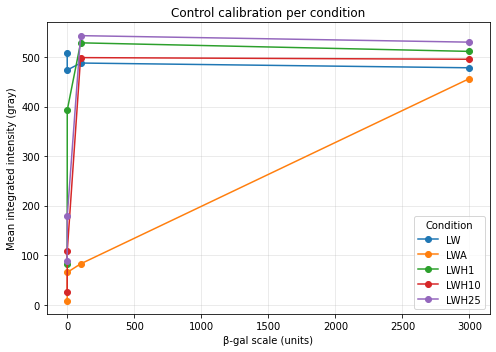

In [16]:
import numpy as np
import matplotlib.pyplot as plt

b_gal_scale = [0, 0.5, 100, 3000]
control_pos  = ['A01', 'B01', 'C01', 'D01']
pos_to_bgal  = dict(zip(control_pos, b_gal_scale))

# Keep only the 4 control positions
media_ctrls_1_to_4 = media_ctrls[media_ctrls["scoring_pos"].isin(control_pos)].copy()

# Compute mean intensity per (condition, control_pos)
means = (media_ctrls_1_to_4
         .groupby(["condition_name", "scoring_pos"])["per_well_integrated_intensity_gray"]
         .mean()
         .unstack("scoring_pos")
         .reindex(columns=control_pos))  # ensure A01,B01,C01,D01 order

x = np.array([pos_to_bgal[p] for p in control_pos], dtype=float)

plt.figure(figsize=(7,5))
for condition, row in means.iterrows():
    y = row.values.astype(float)
    plt.plot(x, y, marker='o', label=condition)

plt.xlabel("β-gal scale (units)")
plt.ylabel("Mean integrated intensity (gray)")
plt.title("Control calibration per condition")

# x spans 0 → 3000, so use symlog to keep 0 visible but compress large values
# plt.xscale("symlog", linthresh=0.1)  # linear near 0, log beyond 0.1
plt.grid(True, which="both", alpha=0.3)
plt.legend(title="Condition")
plt.tight_layout()
plt.show()


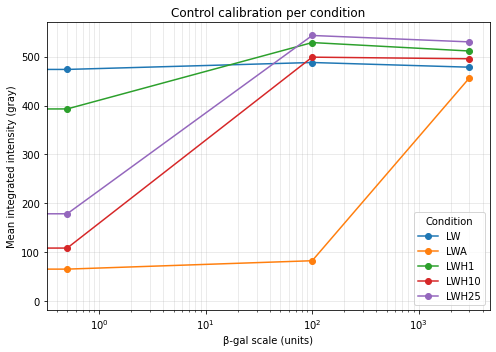

In [17]:
import numpy as np
import matplotlib.pyplot as plt

b_gal_scale = [0, 0.5, 100, 3000]
control_pos  = ['A01', 'B01', 'C01', 'D01']
pos_to_bgal  = dict(zip(control_pos, b_gal_scale))

# Keep only the 4 control positions
media_ctrls_1_to_4 = media_ctrls[media_ctrls["scoring_pos"].isin(control_pos)].copy()

# Compute mean intensity per (condition, control_pos)
means = (media_ctrls_1_to_4
         .groupby(["condition_name", "scoring_pos"])["per_well_integrated_intensity_gray"]
         .mean()
         .unstack("scoring_pos")
         .reindex(columns=control_pos))  # ensure A01,B01,C01,D01 order

x = np.array([pos_to_bgal[p] for p in control_pos], dtype=float)

plt.figure(figsize=(7,5))
for condition, row in means.iterrows():
    y = row.values.astype(float)
    plt.plot(x, y, marker='o', label=condition)

plt.xlabel("β-gal scale (units)")
plt.ylabel("Mean integrated intensity (gray)")
plt.title("Control calibration per condition")

# x spans 0 → 3000, so use symlog to keep 0 visible but compress large values
plt.xscale("log")#, linthresh=0.1)  # linear near 0, log beyond 0.1
plt.grid(True, which="both", alpha=0.3)
plt.legend(title="Condition")
plt.tight_layout()
plt.show()


In [18]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr

b_gal_scale = [0, 0.5, 100, 3000]
control_pos = ['A01', 'B01', 'C01', 'D01']
pos_to_bgal = dict(zip(control_pos, b_gal_scale))

# Keep only the four control positions
media_ctrls_1_to_4 = media_ctrls[media_ctrls["scoring_pos"].isin(control_pos)].copy()

# Mean intensity for each (condition, control_pos)
means = (media_ctrls_1_to_4
         .groupby(["condition_name", "scoring_pos"])["per_well_integrated_intensity_gray"]
         .mean()
         .unstack("scoring_pos")
         .reindex(columns=control_pos))  # enforce A01→D01 order

results = []

for condition, row in means.iterrows():
    y = row.values.astype(float)
    
    # Drop NaNs in case a position is missing
    mask = ~np.isnan(y)
    if mask.sum() < 2:
        continue  # skip if too few points for correlation
    
    # Pearson correlation
    r, pval = pearsonr(np.array(b_gal_scale)[mask], y[mask])
    results.append((condition, r, pval))

# Convert to DataFrame and sort
corr_df = pd.DataFrame(results, columns=["condition_name", "pearson_r", "p_value"])
corr_df = corr_df.sort_values("pearson_r", ascending=False)

print(corr_df)


  condition_name  pearson_r   p_value
1            LWA   0.990829  0.009171
3          LWH10   0.593191  0.406809
4          LWH25   0.577266  0.422734
2           LWH1   0.448432  0.551568
0             LW  -0.383426  0.616574


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages

# Get unique retest_batches and condition_names
retest_batches = media_ctrls['retest_batch'].unique()
condition_names = ['LW', 'LWH1', 'LWH10', 'LWH25', 'LWA']

# Create a single figure with subplots for all batches and conditions
n_batches = len(retest_batches)
n_conditions = len(condition_names)

# Create PDF file
with PdfPages(f'{outputs_dir}/sqY2H/media_controls_density_plots.pdf') as pdf:
    fig, axes = plt.subplots(n_batches, n_conditions, figsize=(5*n_conditions, 4*n_batches), sharex=True)#, sharey=True)
    
    # Handle case where there's only one batch
    if n_batches == 1:
        axes = axes.reshape(1, -1)
    # Handle case where there's only one condition
    if n_conditions == 1:
        axes = axes.reshape(-1, 1)
    
    fig.suptitle('Media Controls Density Plots - All Batches', fontsize=16)
    
    for batch_idx, batch in enumerate(retest_batches):
        # Filter data for this batch
        batch_data = media_ctrls[media_ctrls['retest_batch'] == batch]
        
        for condition_idx, condition in enumerate(condition_names):
            ax = axes[batch_idx, condition_idx]
            condition_data = batch_data[batch_data['condition_name'] == condition]
            
            if len(condition_data) > 0:
                # Get unique scoring_pos for this condition
                scoring_positions = condition_data['scoring_pos'].unique()
                
                for pos in scoring_positions:
                    pos_data = condition_data[condition_data['scoring_pos'] == pos]
                    values = pos_data['per_well_integrated_intensity_gray'].values
                    
                    if len(values) > 0:
                        # Create density curve using seaborn kdeplot
                        sns.kdeplot(x=values, label=f'{pos}', alpha=0.7, linewidth=2, ax=ax)
            
            # Set titles and labels
            if batch_idx == 0:
                ax.set_title(f'{condition}', fontsize=12)
            if condition_idx == 0:
                ax.set_ylabel(f'Batch {batch}\nDensity', fontsize=10)
            if batch_idx == n_batches - 1:
                ax.set_xlabel('per_well_integrated_intensity_gray', fontsize=10)
            
            ax.set_xlim(left=0)
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    plt.close()

print("PDF saved as 'media_controls_density_plots.pdf'")

PDF saved as 'media_controls_density_plots.pdf'


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


95th percentile of MADs: 179.3738266281783


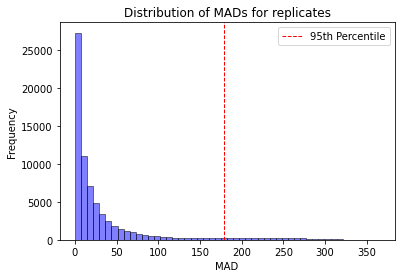

Number of replicates with MAD below 95th percentile: 66674
Total number of replicates: 71706


In [20]:
mads = []

mads_tuples = []

for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
    scores = df['per_well_integrated_intensity_gray'].dropna().values
    scores_nan = df['per_well_integrated_intensity_gray'].values
    # compute the Median absolute deviation (MAD) of the scores
    median = np.median(scores)
    mean = np.mean(scores)
    mad = np.median(np.abs(scores - median))
    mads.append(mad)
    mads_tuples.append((mad, scores, median, mean))
    # if np.isnan(mad):
        # print(f"Group {group} has NaN MAD with scores: {scores_nan}")

# 95th percentile of MADs, dropping NaNs first
mads_no_nan = [mad for mad in mads if not np.isnan(mad)]
mad_95 = np.percentile(mads_no_nan, 95)
print(f"95th percentile of MADs: {mad_95}")

plt.hist(mads, bins=50, alpha=0.5, color='blue', edgecolor='black')
plt.axvline(mad_95, color='red', linestyle='dashed', linewidth=1, label='95th Percentile')
plt.xlabel('MAD')
plt.ylabel('Frequency')
plt.title('Distribution of MADs for replicates')
plt.legend()
plt.show()

# count the number of replicates with MAD below the 95th percentile
num_below_95 = sum(mad < mad_95 for mad in mads)
print(f"Number of replicates with MAD below 95th percentile: {num_below_95}")
print(f"Total number of replicates: {len(mads)}")


In [21]:
# sorted_mads_tuples = sorted(
#     [x for x in mads_tuples if not np.isnan(x[0])],
#     key=lambda x: x[0],
#     reverse=True
# )
# for mad, scores, median, mean in sorted_mads_tuples:
#     print(scores)
#     print(f"MAD: {mad}, Median: {median}, Mean: {mean}")
#     print()

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


95th percentile of mads_log2: 1.1826697233677714


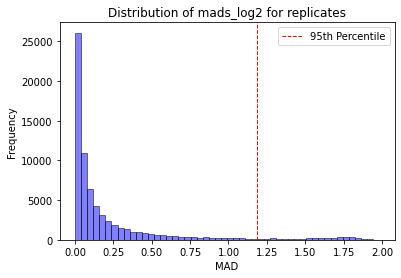

Number of replicates with MAD below 95th percentile: 66674
Total number of replicates: 71706


In [22]:
mads_log2 = []

mads_tuples_log2 = []

for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
    scores = df['automated_log2'].dropna().values
    scores_nan = df['automated_log2'].values
    # compute the Median absolute deviation (MAD) of the scores
    median = np.median(scores)
    mean = np.mean(scores)
    mad = np.median(np.abs(scores - median))
    mads_log2.append(mad)
    
    scores_nolog = df['per_well_integrated_intensity_gray'].dropna().values
    scores_nan_nolog = df['per_well_integrated_intensity_gray'].values
    # compute the Median absolute deviation (MAD) of the scores
    median_nolog = np.median(scores_nolog)
    mean_nolog = np.mean(scores_nolog)
    mad_nolog = np.median(np.abs(scores_nolog - median_nolog))
    # mads.append(mad)
    no_log_tuple = (mad_nolog, scores_nolog, median_nolog, mean_nolog)
    mads_tuples_log2.append((mad, scores, median, mean, no_log_tuple))
    
    # mads_tuples.append((mad, scores, median, mean))
    # mads
    # if np.isnan(mad):
        # print(f"Group {group} has NaN MAD with scores: {scores_nan}")

# 95th percentile of MADs, dropping NaNs first
mads_log2_no_nan = [mad for mad in mads_log2 if not np.isnan(mad)]
mad_95_log2 = np.percentile(mads_log2_no_nan, 95)
print(f"95th percentile of mads_log2: {mad_95_log2}")

plt.hist(mads_log2, bins=50, alpha=0.5, color='blue', edgecolor='black')
plt.axvline(mad_95_log2, color='red', linestyle='dashed', linewidth=1, label='95th Percentile')
plt.xlabel('MAD')
plt.ylabel('Frequency')
plt.title('Distribution of mads_log2 for replicates')
plt.legend()
plt.show()

# count the number of replicates with MAD below the 95th percentile
num_below_95 = sum(mad < mad_95_log2 for mad in mads_log2)
print(f"Number of replicates with MAD below 95th percentile: {num_below_95}")
print(f"Total number of replicates: {len(mads_log2)}")


In [23]:
# sorted_mads_tuples_log2 = sorted(
#     [x for x in mads_tuples_log2 if not np.isnan(x[0])],
#     key=lambda x: x[0],
#     reverse=True
# )
# for mad, scores, median, mean, nolog_tuple in sorted_mads_tuples_log2:
#     print(scores)
#     print(f"MAD: {mad}, Median: {median}, Mean: {mean}\nNo Log Tuple: {nolog_tuple}")
#     print()

In [24]:
# mads

Number of groups with consensus score: 66018
Number of groups without consensus score: 5688
Total number of groups: 71706
Percentage of groups with consensus score: 92.07%


<Axes: ylabel='Frequency'>

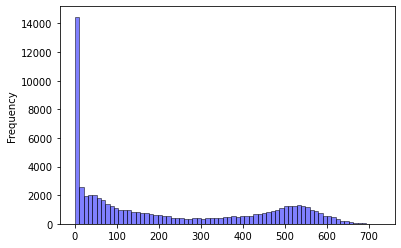

In [25]:
# Compute consensus scores for replicates with MAD below the 95th percentile by taking the mean of the scores and adding it to a new column 'consensus_score'
auto_df['consensus_score'] = np.nan
auto_df['consensus_score'] = auto_df.groupby(
    ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']
)['per_well_integrated_intensity_gray'].transform(
    lambda x: np.mean(x.dropna()) if len(x.dropna()) > 2 and np.median(np.abs(x.dropna() - np.median(x.dropna()))) < mad_95 else np.nan
)

auto_df_full = auto_df.copy()

# Remove duplicate rows - keep only one row per group after consensus calculation
auto_df = auto_df.drop_duplicates(subset=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']).reset_index(drop=True)



# Count groups with and without consensus scores more efficiently
consensus_summary = auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'])['consensus_score'].first().notna()
consensus_count = consensus_summary.sum()
no_consensus_count = len(consensus_summary) - consensus_count

print(f"Number of groups with consensus score: {consensus_count}")
print(f"Number of groups without consensus score: {no_consensus_count}")
print(f"Total number of groups: {len(consensus_summary)}")
print(f"Percentage of groups with consensus score: {consensus_count / len(consensus_summary) * 100:.2f}%")
auto_df['consensus_score'].plot(kind='hist', bins=70, alpha=0.5, color='blue', edgecolor='black')

In [32]:
auto_df[(auto_df.db_orf_id == '7982.0') &
        (auto_df.db_mut_id == 202799.0)]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score
16231,VUSAPWT1B2r01_033,A09,VUSAPWT1B2r01_031_032_033_034_035_036,VUSAPWT1B2,r07,LW,1.0,False,2860.0,NaN,...,202799.0,VUSMutY8Dh031,B04,CEGSint_Y8A_3,D10,4.0,528.700667,False,9.176673,479.434651
16255,VUSAPWT1B2r01_033,C09,VUSAPWT1B2r01_031_032_033_034_035_036,VUSAPWT1B2,r07,LW,1.0,False,7982.0,NaN,...,202799.0,VUSMutY8Dh031,B04,CEGSint_Y8A_6,G10,4.0,500.537264,False,9.104696,477.098375
16393,VUSAPWT1B2r01_033,O07,VUSAPWT1B2r01_031_032_033_034_035_036,VUSAPWT1B2,r07,LW,1.0,False,0.0,NaN,...,202799.0,VUSMutY8Dh031,B04,CEGSint_Y8A1_2_6,E01,4.0,554.712440,False,9.240105,560.985646
20093,VUSAPWT1B2r02_033,A09,VUSAPWT1B2r02_031_032_033_034_035_036,VUSAPWT1B2,r08,LWA,1.0,False,2860.0,NaN,...,202799.0,VUSMutY8Dh031,B04,CEGSint_Y8A_3,D10,4.0,0.000000,False,5.643856,NaN
20117,VUSAPWT1B2r02_033,C09,VUSAPWT1B2r02_031_032_033_034_035_036,VUSAPWT1B2,r08,LWA,1.0,False,7982.0,NaN,...,202799.0,VUSMutY8Dh031,B04,CEGSint_Y8A_6,G10,4.0,537.648388,False,9.198809,512.240864
20255,VUSAPWT1B2r02_033,O07,VUSAPWT1B2r02_031_032_033_034_035_036,VUSAPWT1B2,r08,LWA,1.0,False,0.0,NaN,...,202799.0,VUSMutY8Dh031,B04,CEGSint_Y8A1_2_6,E01,2.0,15.101961,False,6.024629,87.204903
23955,VUSAPWT1B2r03_033,A09,VUSAPWT1B2r03_031_032_033_034_035_036,VUSAPWT1B2,r09,LWH1,1.0,False,2860.0,NaN,...,202799.0,VUSMutY8Dh031,B04,CEGSint_Y8A_3,D10,4.0,616.043167,False,9.379472,609.602317
23979,VUSAPWT1B2r03_033,C09,VUSAPWT1B2r03_031_032_033_034_035_036,VUSAPWT1B2,r09,LWH1,1.0,False,7982.0,NaN,...,202799.0,VUSMutY8Dh031,B04,CEGSint_Y8A_6,G10,3.0,552.654924,False,9.235188,552.984989
24117,VUSAPWT1B2r03_033,O07,VUSAPWT1B2r03_031_032_033_034_035_036,VUSAPWT1B2,r09,LWH1,1.0,False,0.0,NaN,...,202799.0,VUSMutY8Dh031,B04,CEGSint_Y8A1_2_6,E01,2.0,556.286295,False,9.243855,483.863744
27817,VUSAPWT1B2r04_033,A09,VUSAPWT1B2r04_031_032_033_034_035_036,VUSAPWT1B2,r10,LWH10,1.0,False,2860.0,NaN,...,202799.0,VUSMutY8Dh031,B04,CEGSint_Y8A_3,D10,4.0,0.000000,False,5.643856,NaN


In [26]:
# ...existing code...
# Group-level summary (one row per group after drop_duplicates)
grp_summary = (
    auto_df
    .assign(kept=auto_df['consensus_score'].notna())
    .groupby('condition_name')
    .agg(total_groups=('kept', 'size'),
         kept_groups=('kept', 'sum'))
    .reset_index()
)
grp_summary['dropped_groups'] = grp_summary['total_groups'] - grp_summary['kept_groups']
grp_summary['pct_kept'] = (grp_summary['kept_groups'] / grp_summary['total_groups'] * 100).round(2)
print("Groups kept/dropped per condition_name:")
print(grp_summary.sort_values('condition_name'))

# Replicate-level summary (count rows in groups that pass/fail the rule)
group_cols = ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']
def group_passes(s):
    vals = s.dropna().values
    return (len(vals) > 2) and (np.median(np.abs(vals - np.median(vals))) < mad_95)

auto_df_full['group_passed'] = auto_df_full.groupby(group_cols)['per_well_integrated_intensity_gray'].transform(group_passes)

rep_summary = (
    auto_df_full
    .groupby('condition_name')
    .agg(total_rows=('group_passed', 'size'),
         kept_rows=('group_passed', 'sum'))
    .reset_index()
)
rep_summary['dropped_rows'] = rep_summary['total_rows'] - rep_summary['kept_rows']
rep_summary['pct_rows_in_kept_groups'] = (rep_summary['kept_rows'] / rep_summary['total_rows'] * 100).round(2)

print("\nReplicate rows belonging to kept/dropped groups per condition_name:")
print(rep_summary.sort_values('condition_name'))
# ...existing code...

Groups kept/dropped per condition_name:
  condition_name  total_groups  kept_groups  dropped_groups  pct_kept
0             LW         12035        10403            1632     86.44
1            LWA         12035        10957            1078     91.04
2          LWAH1         12035        11107             928     92.29
3           LWH1         12035        11067             968     91.96
4          LWH10         12035        11020            1015     91.57
5          LWH25         12035        11464             571     95.26


TypeError: Expected numeric dtype, got object instead.

In [ ]:
# for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
#     print('Replicates', df.per_well_integrated_intensity_gray.values)
#     print('Consensus score', df.consensus_score.values[0])
#     print('---')

In [ ]:
# map ad_orf_id to ad_symbol

mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

# Convert to polars for mapping
auto_df_pl = pl.DataFrame(auto_df)

# Ensure join key types match - cast to string
auto_df_pl = auto_df_pl.with_columns([
    pl.col("db_orf_id").cast(pl.String),
    pl.col("db_mut_id").cast(pl.String)
])

auto_df_pl = auto_df_pl.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)

# merge with metadata and write out table
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.String).alias("db_mut_id")
)

auto_df_pl = auto_df_pl.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
auto_df_pl.write_csv(f"{outputs_dir}/sqY2H/2_automated_raw_consensus_scores.csv")

# Convert back to pandas if needed
auto_df = auto_df_pl.to_pandas()
auto_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,None,None,None,None,None,None,None,NaN,NaN,None
1,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6
2,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,NR0B1,None,None,ENSG00000169297,None,None,NaN,NaN,NR0B1
3,VUSAPWT1B1r01_001,A07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,279.0,NaN,...,CALCOCO2,None,None,None,None,None,None,NaN,NaN,None
4,VUSAPWT1B1r01_001,A09,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,KCNJ2,None,None,ENSG00000123700,None,None,NaN,NaN,KCNJ2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72206,VUSAPWT1B1r06_036,O13,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100063955.0,NaN,...,N4BP1,LITAF,Leu122Val,364C>G,ENSG00000189067,Edgotyping3,1_Pathogenic,NaN,NaN,LITAF_Leu122Val
72207,VUSAPWT1B1r06_036,O15,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,3598.0,NaN,...,DAZAP2,LITAF,Leu122Val,364C>G,ENSG00000189067,Edgotyping3,1_Pathogenic,NaN,NaN,LITAF_Leu122Val
72208,VUSAPWT1B1r06_036,O17,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,53212.0,NaN,...,ROPN1,PKP2,Ala372Pro,1114G>C,ENSG00000057294,Edgotyping3,3_Conflicting,NaN,1.0,PKP2_Ala372Pro
72209,VUSAPWT1B1r06_036,O19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,SPTA1,PKP2,Phe424Ser,1271T>C,ENSG00000057294,Edgotyping3,4_VUS,NaN,2.0,PKP2_Phe424Ser


In [ ]:
auto_df.per_well_integrated_intensity_gray.value_counts()

per_well_integrated_intensity_gray
0.000000      15946
3.265360          4
4.167320          3
4.794771          3
4.299346          3
              ...  
300.169942        1
101.783008        1
537.827472        1
569.477150        1
171.039218        1
Name: count, Length: 53639, dtype: int64

In [ ]:
ppi_group_set = ['71892_71892_3998_VUSAPWT1B1',
 '152_71337_0_VUSAPWT1B1',
 '4361_386_213660_VUSAPWT1B2',
 '3598_52920_218636_VUSAPWT1B1',
 '100011278_13939_204115_VUSAPWT1B2',
 '11229_4870_215298_VUSAPWT1B2',
 '5793_4062_201426_VUSAPWT2B1',
 '6281_100016069_2659_VUSAPWT6B1',
 '55351_2920_214386_VUSAPWT1B2',
 '100070143_13320_204012_VUSAPWT1B2',
 '6446_4062_201424_VUSAPWT6B1',
 '2860_7982_0_VUSAPWT1B2',
 '199_7652_1794_VUSAPWT6B1',
 '54784_3689_214861_VUSAPWT6B1',
 '208_5066_201832_VUSAPWT1B2',
 '5894_4043_0_VUSAPWT1B2',
 '71163_52920_2673_VUSAPWT2B1',
 '100015161_3980_201374_VUSAPWT2B1',
 '14408_2713_200902_VUSAPWT6B1',
 '11130_4062_201429_VUSAPWT6B1',
 '6171_5066_0_VUSAPWT6B1',
 '1611_2713_200868_VUSAPWT1B1',
 '53025_3180_214556_VUSAPWT1B2',
 '6644_5723_201966_VUSAPWT6B1',
 '2522_7652_1799_VUSAPWT1B1',
 '2522_7652_1837_VUSAPWT1B1',
 '244_8965_216770_VUSAPWT1B2',
 '4621_4723_201725_VUSAPWT1B1',
 '4759_5066_201830_VUSAPWT1B2',
 '4692_4692_0_VUSAPWT1B2',
 '53942_8151_202847_VUSAPWT1B2',
 '1172_4062_201423_VUSAPWT6B1',
 '5793_4062_201424_VUSAPWT2B1',
 '55664_4870_215281_VUSAPWT1B2',
 '2347_7675_202587_VUSAPWT1B2',
 '1863_52920_2685_VUSAPWT1B1',
 '8843_2713_449_VUSAPWT2B1',
 '71704_11805_2156_VUSAPWT1B1',
 '7233_7652_1811_VUSAPWT1B1',
 '3490_8999_202979_VUSAPWT1B2',
 '13235_3535_0_VUSAPWT6B1',
 '71163_52920_2667_VUSAPWT2B1',
 '2654_2654_214307_VUSAPWT1B2',
 '71963_2713_200798_VUSAPWT6B1',
 '5081_6408_215945_VUSAPWT2B1',
 '2522_7652_1820_VUSAPWT1B1',
 '54668_14966_0_VUSAPWT1B2',
 '6171_5066_201830_VUSAPWT6B1',
 '54869_3980_201375_VUSAPWT2B1',
 '8359_11805_2183_VUSAPWT1B1',
 '6446_4062_201427_VUSAPWT6B1',
 '14387_7652_1801_VUSAPWT6B1',
 '71152_14966_218513_VUSAPWT1B2',
 '56442_71191_205704_VUSAPWT1B2',
 '8186_4062_201426_VUSAPWT2B1',
 '5441_71892_4018_VUSAPWT1B1',
 '6281_100016069_2616_VUSAPWT6B1',
 '6534_8420_216668_VUSAPWT1B2',
 '4872_5066_201830_VUSAPWT2B1',
 '13662_70497_3867_VUSAPWT1B1',
 '56215_52920_2686_VUSAPWT1B1',
 '6490_2920_214430_VUSAPWT2B1',
 '824_3535_6159_VUSAPWT1B1',
 '2831_6408_215945_VUSAPWT6B1',
 '54668_14966_218513_VUSAPWT1B2',
 '8447_4062_201426_VUSAPWT6B1',
 '11132_52920_2669_VUSAPWT1B1',
 '3598_52920_2671_VUSAPWT1B1',
 '71704_11805_2147_VUSAPWT1B1',
 '53964_2713_200837_VUSAPWT1B1',
 '4759_5066_0_VUSAPWT1B2',
 '8447_4062_201422_VUSAPWT6B1',
 '1586_3727_214876_VUSAPWT1B2',
 '3490_8999_202976_VUSAPWT1B2',
 '53964_2713_200850_VUSAPWT1B1',
 '56139_4062_201428_VUSAPWT6B1',
 '12260_2651_214298_VUSAPWT1B1',
 '7233_7652_1846_VUSAPWT1B1',
 '11229_4870_215295_VUSAPWT1B2',
 '100000407_53965_204889_VUSAPWT1B2',
 '6963_7167_216179_VUSAPWT1B1',
 '1611_2713_472_VUSAPWT1B1',
 '3490_8999_202988_VUSAPWT1B2',
 '13662_70497_3882_VUSAPWT1B1',
 '5093_5723_201962_VUSAPWT1B2',
 '6534_8420_0_VUSAPWT1B2',
 '14408_2713_200850_VUSAPWT6B1',
 '4621_4723_201745_VUSAPWT1B1',
 '14387_7652_1846_VUSAPWT6B1',
 '3522_3020_0_VUSAPWT1B2',
 '4621_4723_201728_VUSAPWT1B1',
 '71152_14966_218511_VUSAPWT1B2',
 '8359_11805_2155_VUSAPWT1B1',
 '55351_2920_214442_VUSAPWT1B2',
 '14221_14221_218279_VUSAPWT1B2',
 '4621_4723_201750_VUSAPWT1B1',
 '13768_71191_0_VUSAPWT6B1',
 '72108_71191_0_VUSAPWT6B1',
 '100010307_6983_0_VUSAPWT1B2',
 '2012_4062_201428_VUSAPWT6B1',
 '7233_7652_1818_VUSAPWT1B1',
 '13768_71191_205705_VUSAPWT6B1',
 '14910_14910_218493_VUSAPWT1B2',
 '2845_4043_201415_VUSAPWT1B2',
 '70989_4062_201431_VUSAPWT6B1',
 '11288_3180_214556_VUSAPWT1B2',
 '1586_3727_214871_VUSAPWT1B2',
 '100011278_13939_0_VUSAPWT1B2',
 '14441_52920_2681_VUSAPWT1B1',
 '71001_52920_2666_VUSAPWT1B1',
 '5453_6408_0_VUSAPWT6B1',
 '439_52920_2682_VUSAPWT6B1',
 '1172_4062_201424_VUSAPWT6B1',
 '53044_71191_0_VUSAPWT1B2',
 '3490_8999_203017_VUSAPWT1B2',
 '2860_7982_202787_VUSAPWT1B2',
 '100067228_71191_205705_VUSAPWT1B2',
 '53610_9866_216928_VUSAPWT1B2',
 '71001_52920_218636_VUSAPWT1B1',
 '70054_52920_2673_VUSAPWT6B1',
 '70054_52920_2662_VUSAPWT6B1',
 '71704_11805_2157_VUSAPWT1B1',
 '100011278_4870_215273_VUSAPWT1B2',
 '5081_6408_215946_VUSAPWT2B1',
 '6490_2920_214419_VUSAPWT2B1',
 '730_52920_2682_VUSAPWT6B1',
 '6802_55855_219414_VUSAPWT1B2',
 '70054_52920_2686_VUSAPWT6B1',
 '14269_2920_214445_VUSAPWT6B1',
 '71163_52920_2675_VUSAPWT2B1',
 '100064009_13939_204115_VUSAPWT1B2',
 '8359_11805_2123_VUSAPWT1B1',
 '281_281_21_VUSAPWT1B1',
 '71892_71892_4004_VUSAPWT1B1',
 '2845_52920_2662_VUSAPWT1B1',
 '1235_52920_2678_VUSAPWT2B1',
 '1235_52920_2686_VUSAPWT2B1',
 '2860_7982_202801_VUSAPWT1B2',
 '199_7652_1834_VUSAPWT6B1',
 '56215_52920_2666_VUSAPWT1B1',
 '71715_52920_2666_VUSAPWT1B1',
 '4761_2713_200856_VUSAPWT1B1',
 '14441_52920_2670_VUSAPWT1B1',
 '5441_71892_4004_VUSAPWT1B1',
 '13662_70497_3858_VUSAPWT1B1',
 '4480_4043_201419_VUSAPWT1B2',
 '1611_2713_473_VUSAPWT1B1',
 '1235_52920_2688_VUSAPWT2B1',
 '71892_71892_0_VUSAPWT1B1',
 '152_5066_201830_VUSAPWT1B2',
 '2920_2920_214437_VUSAPWT1B2',
 '100011278_14966_218521_VUSAPWT1B2',
 '8297_13796_218155_VUSAPWT1B2',
 '53626_3980_0_VUSAPWT2B1',
 '2654_2654_214309_VUSAPWT1B2',
 '12685_71077_220314_VUSAPWT2B1',
 '199_7652_0_VUSAPWT6B1',
 '13662_70497_3815_VUSAPWT1B1',
 '7675_7675_202586_VUSAPWT1B2',
 '54647_3535_6159_VUSAPWT1B1',
 '71892_71892_4005_VUSAPWT1B1',
 '71163_52920_0_VUSAPWT2B1',
 '152_71337_3957_VUSAPWT1B1',
 '54341_2713_838_VUSAPWT1B1',
 '100016069_100016069_2639_VUSAPWT1B1',
 '6791_8143_202838_VUSAPWT1B2',
 '4621_4723_201738_VUSAPWT1B1',
 '53964_2713_838_VUSAPWT1B1',
 '55664_4870_215280_VUSAPWT1B2',
 '100070143_13320_204008_VUSAPWT1B2',
 '5132_5132_215357_VUSAPWT1B2',
 '9117_5066_201831_VUSAPWT2B1',
 '14441_52920_2662_VUSAPWT1B1',
 '70989_3438_201183_VUSAPWT6B1',
 '56139_4062_201423_VUSAPWT6B1',
 '5772_3535_0_VUSAPWT1B1',
 '3490_8999_203015_VUSAPWT1B2',
 '4761_2713_200837_VUSAPWT1B1',
 '55664_4870_0_VUSAPWT1B2',
 '71963_2713_200856_VUSAPWT6B1',
 '13662_70497_3851_VUSAPWT1B1',
 '56215_52920_2682_VUSAPWT1B1',
 '53942_5442_0_VUSAPWT1B2',
 '14221_14221_218278_VUSAPWT1B2',
 '56215_52920_2685_VUSAPWT1B1',
 '71001_52920_218637_VUSAPWT1B1',
 '2522_7652_1825_VUSAPWT1B1',
 '71152_13939_204115_VUSAPWT1B2',
 '6811_4723_201743_VUSAPWT1B1',
 '14232_4062_201433_VUSAPWT2B1',
 '71704_11805_2151_VUSAPWT1B1',
 '439_52920_2684_VUSAPWT6B1',
 '152_71337_3941_VUSAPWT1B1',
 '4761_2713_1005_VUSAPWT1B1',
 '11922_2713_200837_VUSAPWT1B1',
 '71704_11805_2145_VUSAPWT1B1',
 '2615_7652_0_VUSAPWT2B1',
 '100066360_14966_218513_VUSAPWT1B2',
 '13662_6983_216123_VUSAPWT1B2',
 '7233_7652_1831_VUSAPWT1B1',
 '13662_70497_3786_VUSAPWT1B1',
 '7233_7652_13919_VUSAPWT1B1',
 '56139_4062_201432_VUSAPWT6B1',
 '13662_70497_3879_VUSAPWT1B1',
 '14269_2920_214419_VUSAPWT6B1',
 '2615_7652_1831_VUSAPWT2B1',
 '100016069_100016069_2643_VUSAPWT1B1',
 '3490_8999_202991_VUSAPWT1B2',
 '100015161_3980_0_VUSAPWT2B1',
 '70054_52920_2677_VUSAPWT6B1',
 '9342_3535_6171_VUSAPWT1B1',
 '10064_52920_2665_VUSAPWT2B1',
 '5441_71892_4009_VUSAPWT1B1',
 '70054_52920_2685_VUSAPWT6B1',
 '9267_3535_0_VUSAPWT1B1',
 '10064_52920_2674_VUSAPWT2B1',
 '56215_52920_2674_VUSAPWT1B1',
 '3598_52920_2665_VUSAPWT1B1',
 '100062334_6408_0_VUSAPWT6B1',
 '10106_8151_202844_VUSAPWT1B2',
 '55351_5066_201830_VUSAPWT1B2',
 '10821_71191_205705_VUSAPWT2B1',
 '12825_4062_201428_VUSAPWT6B1',
 '4361_386_213661_VUSAPWT1B2',
 '2860_7982_202805_VUSAPWT1B2',
 '100016069_100016069_2641_VUSAPWT1B1',
 '12825_4062_201422_VUSAPWT6B1',
 '152_71337_205772_VUSAPWT1B1',
 '4973_70368_205543_VUSAPWT1B2',
 '70989_4062_201423_VUSAPWT6B1',
 '100016069_100016069_2603_VUSAPWT1B1',
 '2920_2920_214418_VUSAPWT1B2',
 '14404_2713_200902_VUSAPWT6B1',
 '100009390_12739_0_VUSAPWT1B2',
 '2794_13796_218149_VUSAPWT2B1',
 '13795_3535_0_VUSAPWT1B1',
 '11922_2713_472_VUSAPWT1B1',
 '5441_71892_3998_VUSAPWT1B1',
 '71715_52920_2685_VUSAPWT1B1',
 '13662_70497_3873_VUSAPWT1B1',
 '54326_7323_0_VUSAPWT1B1',
 '10556_3535_6161_VUSAPWT1B1',
 '70054_52920_2670_VUSAPWT6B1',
 '53626_3980_201376_VUSAPWT2B1',
 '100016069_100016069_2635_VUSAPWT1B1',
 '4759_5066_201831_VUSAPWT1B2',
 '14269_3535_201190_VUSAPWT6B1',
 '2845_52920_2685_VUSAPWT1B1',
 '100064217_3535_201190_VUSAPWT1B1',
 '13662_70497_3863_VUSAPWT1B1',
 '4761_2713_472_VUSAPWT1B1',
 '100011278_4870_215270_VUSAPWT1B2',
 '14364_5066_0_VUSAPWT2B1',
 '6281_100016069_2656_VUSAPWT6B1',
 '13662_6983_0_VUSAPWT1B2',
 '53964_2713_200818_VUSAPWT1B1',
 '156_71191_205705_VUSAPWT6B1',
 '100070143_13320_204015_VUSAPWT1B2',
 '70989_3535_0_VUSAPWT6B1',
 '3598_52920_0_VUSAPWT1B1',
 '3110_71191_0_VUSAPWT2B1',
 '2920_2920_0_VUSAPWT1B2',
 '5593_3980_201375_VUSAPWT2B1',
 '3110_71191_205704_VUSAPWT2B1',
 '3110_71191_205705_VUSAPWT2B1',
 '10441_71337_205772_VUSAPWT6B1',
 '6811_4723_201745_VUSAPWT1B1',
 '4761_2713_200818_VUSAPWT1B1',
 '100000046_7323_0_VUSAPWT6B1',
 '71715_52920_2689_VUSAPWT1B1',
 '100016069_100016069_2616_VUSAPWT1B1',
 '100010307_6983_216121_VUSAPWT1B2',
 '10471_5442_0_VUSAPWT1B2',
 '9746_54308_218855_VUSAPWT1B1',
 '100011278_14966_218513_VUSAPWT1B2',
 '14269_2920_214394_VUSAPWT6B1',
 '4759_5066_201832_VUSAPWT1B2',
 '14387_7652_1832_VUSAPWT6B1',
 '439_52920_218636_VUSAPWT6B1',
 '8297_13796_218147_VUSAPWT1B2',
 '11922_2713_1005_VUSAPWT1B1',
 '3598_52920_2686_VUSAPWT1B1',
 '2522_7652_1818_VUSAPWT1B1',
 '70054_52920_2665_VUSAPWT6B1',
 '11132_52920_2673_VUSAPWT1B1',
 '53886_2713_200902_VUSAPWT6B1',
 '1190_71191_0_VUSAPWT1B2',
 '2845_52920_2686_VUSAPWT1B1',
 '70073_5066_0_VUSAPWT2B1',
 '71715_52920_2677_VUSAPWT1B1',
 '71001_52920_2688_VUSAPWT1B1',
 '53886_2713_0_VUSAPWT6B1',
 '13662_70497_3785_VUSAPWT1B1',
 '2920_2920_214442_VUSAPWT1B2',
 '281_281_19_VUSAPWT1B1',
 '54341_2713_1005_VUSAPWT1B1',
 '14408_2713_449_VUSAPWT6B1',
 '8843_2713_200837_VUSAPWT2B1',
 '14441_52920_2682_VUSAPWT1B1',
 '6644_5723_201967_VUSAPWT6B1',
 '13662_70497_3874_VUSAPWT1B1',
 '13600_13939_0_VUSAPWT1B2',
 '3490_8999_202989_VUSAPWT1B2',
 '53702_7323_0_VUSAPWT6B1',
 '199_7652_1824_VUSAPWT6B1',
 '2500_2713_200868_VUSAPWT1B1',
 '56215_52920_2688_VUSAPWT1B1',
 '55351_2920_214397_VUSAPWT1B2',
 '13662_70497_0_VUSAPWT1B1',
 '14338_513_0_VUSAPWT6B1',
 '100016069_100016069_2617_VUSAPWT1B1',
 '824_3980_0_VUSAPWT1B2',
 '55664_4870_215273_VUSAPWT1B2',
 '6490_2920_214442_VUSAPWT2B1',
 '54869_3980_201376_VUSAPWT2B1',
 '54668_71337_3938_VUSAPWT1B1',
 '676_71191_205705_VUSAPWT6B1',
 '100016069_100016069_2630_VUSAPWT1B1',
 '71704_11805_2123_VUSAPWT1B1',
 '6598_3180_0_VUSAPWT6B1',
 '100070143_13320_203998_VUSAPWT1B2',
 '54668_13939_204115_VUSAPWT1B2',
 '13795_3535_6161_VUSAPWT1B1',
 '2918_3180_0_VUSAPWT6B1',
 '71892_71892_4018_VUSAPWT1B1',
 '7233_7652_1794_VUSAPWT1B1',
 '8447_4062_201423_VUSAPWT6B1',
 '55664_4870_215298_VUSAPWT1B2',
 '4351_2713_200818_VUSAPWT6B1',
 '2500_2713_200818_VUSAPWT1B1',
 '10064_52920_218636_VUSAPWT2B1',
 '14404_2713_449_VUSAPWT6B1',
 '14269_2920_214388_VUSAPWT6B1',
 '10906_3180_214556_VUSAPWT1B2',
 '13662_70497_3881_VUSAPWT1B1',
 '4946_4062_201433_VUSAPWT1B2',
 '11922_2713_200818_VUSAPWT1B1',
 '8101_513_0_VUSAPWT1B2',
 '10441_71337_205770_VUSAPWT6B1',
 '11132_52920_2681_VUSAPWT1B1',
 '53964_2713_473_VUSAPWT1B1',
 '71715_52920_0_VUSAPWT1B1',
 '14338_513_213754_VUSAPWT6B1',
 '53964_2713_449_VUSAPWT1B1',
 '53942_8151_202843_VUSAPWT1B2',
 '11567_52920_218636_VUSAPWT1B1',
 '1611_2713_0_VUSAPWT1B1',
 '71704_11805_2137_VUSAPWT1B1',
 '2767_2767_214361_VUSAPWT1B2',
 '71163_52920_2669_VUSAPWT2B1',
 '53942_3535_6161_VUSAPWT1B1',
 '10064_52920_218637_VUSAPWT2B1',
 '6490_2920_214409_VUSAPWT2B1',
 '3490_8999_203011_VUSAPWT1B2',
 '2778_71191_205705_VUSAPWT2B1',
 '6811_4723_201747_VUSAPWT1B1',
 '14387_7652_1824_VUSAPWT6B1',
 '14404_2713_0_VUSAPWT6B1',
 '7233_7652_1817_VUSAPWT1B1',
 '1235_52920_2681_VUSAPWT2B1',
 '71715_52920_2688_VUSAPWT1B1',
 '71704_11805_2139_VUSAPWT1B1',
 '1863_52920_2689_VUSAPWT1B1',
 '11567_52920_2665_VUSAPWT1B1',
 '13662_70497_3843_VUSAPWT1B1',
 '6446_4062_201426_VUSAPWT6B1',
 '70073_5066_201831_VUSAPWT2B1',
 '152_71337_3938_VUSAPWT1B1',
 '2845_52920_218637_VUSAPWT1B1',
 '13662_70497_3878_VUSAPWT1B1',
 '1969_513_213753_VUSAPWT6B1',
 '8186_4062_201422_VUSAPWT2B1',
 '11288_3180_0_VUSAPWT1B2',
 '71178_8143_202840_VUSAPWT1B2',
 '12260_2651_214302_VUSAPWT1B1',
 '7845_386_213658_VUSAPWT1B2',
 '56442_71191_0_VUSAPWT1B2',
 '14387_7652_1798_VUSAPWT6B1',
 '9746_54308_3106_VUSAPWT1B1',
 '1863_52920_2677_VUSAPWT1B1',
 '54647_3535_0_VUSAPWT1B1',
 '14398_3180_214556_VUSAPWT1B2',
 '100011278_13939_204120_VUSAPWT1B2',
 '8359_11805_2139_VUSAPWT1B1',
 '11816_4062_201429_VUSAPWT2B1',
 '100067112_888_200363_VUSAPWT1B2',
 '2920_2920_214430_VUSAPWT1B2',
 '56644_54175_0_VUSAPWT1B2',
 '2615_7652_1842_VUSAPWT2B1',
 '100080183_71191_205704_VUSAPWT6B1',
 '10064_52920_2666_VUSAPWT2B1',
 '7982_7982_202790_VUSAPWT1B2',
 '1190_71191_205704_VUSAPWT1B2',
 '4946_4062_201432_VUSAPWT1B2',
 '54784_3689_214825_VUSAPWT6B1',
 '100066360_55855_219414_VUSAPWT1B2',
 '4872_71191_205704_VUSAPWT2B1',
 '53886_5442_215414_VUSAPWT1B2',
 '2860_7982_202788_VUSAPWT1B2',
 '14387_7652_1807_VUSAPWT6B1',
 '439_52920_2662_VUSAPWT6B1',
 '5772_3535_6172_VUSAPWT1B1',
 '11132_52920_2662_VUSAPWT1B1',
 '54647_3535_201190_VUSAPWT1B1',
 '14269_2920_214430_VUSAPWT6B1',
 '8359_11805_2127_VUSAPWT1B1',
 '6534_8420_216667_VUSAPWT1B2',
 '2286_6408_0_VUSAPWT2B1',
 '71715_52920_2681_VUSAPWT1B1',
 '1611_2713_200818_VUSAPWT1B1',
 '3522_3020_214464_VUSAPWT1B2',
 '1235_52920_2666_VUSAPWT2B1',
 '11816_4062_201426_VUSAPWT2B1',
 '11922_2713_449_VUSAPWT1B1',
 '6552_2713_4465_VUSAPWT1B1',
 '71704_11805_2134_VUSAPWT1B1',
 '1586_3180_0_VUSAPWT1B2',
 '2500_2713_200837_VUSAPWT1B1',
 '10677_2713_200902_VUSAPWT2B1',
 '70054_52920_218637_VUSAPWT6B1',
 '11229_4870_215273_VUSAPWT1B2',
 '53886_2713_472_VUSAPWT6B1',
 '11567_52920_218637_VUSAPWT1B1',
 '6534_8420_216662_VUSAPWT1B2',
 '54784_3689_214847_VUSAPWT6B1',
 '4621_4723_201727_VUSAPWT1B1',
 '2794_13796_218147_VUSAPWT2B1',
 '2500_2713_1005_VUSAPWT1B1',
 '10471_5442_215414_VUSAPWT1B2',
 '8359_11805_20082_VUSAPWT1B1',
 '55351_5066_201831_VUSAPWT1B2',
 '5894_4043_201415_VUSAPWT1B2',
 '1446_3980_201375_VUSAPWT2B1',
 '13813_5585_215440_VUSAPWT1B2',
 '100011278_4870_215274_VUSAPWT1B2',
 '70989_4062_201428_VUSAPWT6B1',
 '71704_11805_2121_VUSAPWT1B1',
 '2522_7652_1811_VUSAPWT1B1',
 '71163_52920_2662_VUSAPWT2B1',
 '4351_2713_1005_VUSAPWT6B1',
 '7845_4043_201415_VUSAPWT1B2',
 '3490_8999_203002_VUSAPWT1B2',
 '14441_52920_2689_VUSAPWT1B1',
 '10064_52920_2684_VUSAPWT2B1',
 '56215_52920_2665_VUSAPWT1B1',
 '54784_3689_214851_VUSAPWT6B1',
 '5441_71892_4003_VUSAPWT1B1',
 '6490_2920_0_VUSAPWT2B1',
 '70989_3438_201179_VUSAPWT6B1',
 '70872_3535_201190_VUSAPWT2B1',
 '56215_52920_2687_VUSAPWT1B1',
 '13662_5066_201830_VUSAPWT1B2',
 '2845_52920_2670_VUSAPWT1B1',
 '10820_7215_0_VUSAPWT6B1',
 '53942_8151_202848_VUSAPWT1B2',
 '10064_52920_2671_VUSAPWT2B1',
 '100011278_4870_215276_VUSAPWT1B2',
 '100016069_100016069_2604_VUSAPWT1B1',
 '8359_11805_2113_VUSAPWT1B1',
 '52866_7323_0_VUSAPWT2B1',
 '55664_4870_215290_VUSAPWT1B2',
 '100070143_3535_201190_VUSAPWT1B1',
 '5441_71892_3996_VUSAPWT1B1',
 '100066360_55855_219420_VUSAPWT1B2',
 '3598_52920_2685_VUSAPWT1B1',
 '1668_1668_214086_VUSAPWT1B2',
 '53942_70368_0_VUSAPWT1B2',
 '7982_7982_202803_VUSAPWT1B2',
 '100070143_13320_204018_VUSAPWT1B2',
 '14387_7652_1818_VUSAPWT6B1',
 '2012_4062_0_VUSAPWT6B1',
 '2767_2767_214360_VUSAPWT1B2',
 '71704_11805_203608_VUSAPWT1B1',
 '100066360_55855_219419_VUSAPWT1B2',
 '14232_4062_201427_VUSAPWT2B1',
 '5793_4062_201428_VUSAPWT2B1',
 '5093_5723_201964_VUSAPWT1B2',
 '1190_71191_205705_VUSAPWT1B2',
 '11130_4062_201423_VUSAPWT6B1',
 '55664_4870_215274_VUSAPWT1B2',
 '5065_2455_200621_VUSAPWT1B2',
 '3598_5066_201831_VUSAPWT1B2',
 '2615_7652_1825_VUSAPWT2B1',
 '11746_71191_0_VUSAPWT1B2',
 '11567_52920_2687_VUSAPWT1B1',
 '100015161_3980_201378_VUSAPWT2B1',
 '55664_4870_215289_VUSAPWT1B2',
 '2500_2713_449_VUSAPWT1B1',
 '1235_52920_218637_VUSAPWT2B1',
 '2522_7652_1842_VUSAPWT1B1',
 '53626_3980_201374_VUSAPWT2B1',
 '10064_52920_2686_VUSAPWT2B1',
 '152_5066_201831_VUSAPWT1B2',
 '71704_11805_2140_VUSAPWT1B1',
 '14441_52920_2688_VUSAPWT1B1',
 '54341_2713_200818_VUSAPWT1B1',
 '3490_8999_203008_VUSAPWT1B2',
 '199_7652_1798_VUSAPWT6B1',
 '3523_71191_205705_VUSAPWT2B1',
 '7982_7982_202808_VUSAPWT1B2',
 '12685_71077_0_VUSAPWT2B1',
 '2767_2767_214357_VUSAPWT1B2',
 '2845_4043_201419_VUSAPWT1B2',
 '71892_71892_4003_VUSAPWT1B1',
 '14441_52920_218637_VUSAPWT1B1',
 '9746_54308_3085_VUSAPWT1B1',
 '53025_3180_0_VUSAPWT1B2',
 '13662_70497_3818_VUSAPWT1B1',
 '7845_4043_201419_VUSAPWT1B2',
 '11567_52920_2674_VUSAPWT1B1',
 '8297_13796_218149_VUSAPWT1B2',
 '6534_8420_216656_VUSAPWT1B2',
 '54647_3535_6172_VUSAPWT1B1',
 '55351_2920_214433_VUSAPWT1B2',
 '14387_7652_1802_VUSAPWT6B1',
 '2615_7652_1800_VUSAPWT2B1',
 '6490_2920_214424_VUSAPWT2B1',
 '10106_8151_202847_VUSAPWT1B2',
 '4946_4062_201428_VUSAPWT1B2',
 '1235_52920_2670_VUSAPWT2B1',
 '4621_4723_201739_VUSAPWT1B1',
 '100016069_100016069_0_VUSAPWT1B1',
 '10064_52920_2677_VUSAPWT2B1',
 '100015084_14966_0_VUSAPWT1B2',
 '8359_11805_2136_VUSAPWT1B1',
 '6281_100016069_0_VUSAPWT6B1',
 '4621_4723_8952_VUSAPWT1B1',
 '6490_2920_214445_VUSAPWT2B1',
 '56371_2455_200620_VUSAPWT6B1',
 '100011278_55855_0_VUSAPWT1B2',
 '145_145_0_VUSAPWT1B2',
 '13662_5066_201832_VUSAPWT1B2',
 '56463_3535_6161_VUSAPWT1B1',
 '10064_52920_2662_VUSAPWT2B1',
 '6232_3180_0_VUSAPWT6B1',
 '2615_7652_1806_VUSAPWT2B1',
 '13662_7465_0_VUSAPWT1B2',
 '14910_14910_218501_VUSAPWT1B2',
 '6963_7167_216175_VUSAPWT1B1',
 '13182_70368_0_VUSAPWT6B1',
 '100011278_55855_219419_VUSAPWT1B2',
 '100011278_4870_215281_VUSAPWT1B2',
 '1863_52920_2678_VUSAPWT1B1',
 '2794_13796_218148_VUSAPWT2B1',
 '11922_2713_200902_VUSAPWT1B1',
 '6534_8420_216655_VUSAPWT1B2',
 '71704_11805_2144_VUSAPWT1B1',
 '6853_2713_449_VUSAPWT2B1',
 '11132_52920_2667_VUSAPWT1B1',
 '1172_5723_201967_VUSAPWT6B1',
 '11132_52920_2685_VUSAPWT1B1',
 '2012_4062_201426_VUSAPWT6B1',
 '9746_54308_218854_VUSAPWT1B1',
 '439_52920_2686_VUSAPWT6B1',
 '11132_52920_2675_VUSAPWT1B1',
 '6853_2713_0_VUSAPWT2B1',
 '6811_4723_201730_VUSAPWT1B1',
 '11816_4062_201433_VUSAPWT2B1',
 '14408_2713_200798_VUSAPWT6B1',
 '9342_3535_6159_VUSAPWT1B1',
 '4621_4723_201724_VUSAPWT1B1',
 '100067228_71191_205704_VUSAPWT1B2',
 '71163_52920_2682_VUSAPWT2B1',
 '2500_2713_200798_VUSAPWT1B1',
 '11132_52920_2682_VUSAPWT1B1',
 '6552_2713_200850_VUSAPWT1B1',
 '13662_70497_205584_VUSAPWT1B1',
 '2522_7652_1829_VUSAPWT1B1',
 '6985_3180_214556_VUSAPWT6B1',
 '3490_8999_202999_VUSAPWT1B2',
 '14221_14221_0_VUSAPWT1B2',
 '2615_7652_1817_VUSAPWT2B1',
 '14364_5066_201831_VUSAPWT2B1',
 '199_7652_1805_VUSAPWT6B1',
 '6811_4723_201744_VUSAPWT1B1',
 '6853_2713_473_VUSAPWT2B1',
 '53281_55246_3218_VUSAPWT1B1',
 '55351_2920_214427_VUSAPWT1B2',
 '152_5066_201832_VUSAPWT1B2',
 '10064_52920_2678_VUSAPWT2B1',
 '4692_4692_215210_VUSAPWT1B2',
 '824_3535_201190_VUSAPWT1B1',
 '2860_7982_202790_VUSAPWT1B2',
 '1586_3727_214874_VUSAPWT1B2',
 '70054_52920_2674_VUSAPWT6B1',
 '1863_52920_2669_VUSAPWT1B1',
 '439_52920_2673_VUSAPWT6B1',
 '71704_11805_2167_VUSAPWT1B1',
 '100070143_13320_204009_VUSAPWT1B2',
 '14232_4062_201432_VUSAPWT2B1',
 '8843_2713_200902_VUSAPWT2B1',
 '1863_52920_2665_VUSAPWT1B1',
 '11922_2713_4554_VUSAPWT1B1',
 '281_281_5_VUSAPWT1B1',
 '70054_52920_2687_VUSAPWT6B1',
 '13182_70368_205543_VUSAPWT6B1',
 '100064217_3535_0_VUSAPWT1B1',
 '4973_70368_0_VUSAPWT1B2',
 '676_71191_0_VUSAPWT6B1',
 '2533_55246_0_VUSAPWT1B1',
 '70759_3535_0_VUSAPWT6B1',
 '71704_11805_0_VUSAPWT1B1',
 '71963_2713_200837_VUSAPWT6B1',
 '6232_3180_214556_VUSAPWT6B1',
 '10064_52920_2667_VUSAPWT2B1',
 '14232_4062_201422_VUSAPWT2B1',
 '11229_4870_0_VUSAPWT1B2',
 '14269_2920_214427_VUSAPWT6B1',
 '2767_2767_0_VUSAPWT1B2',
 '71001_52920_2682_VUSAPWT1B1',
 '53964_2713_200832_VUSAPWT1B1',
 '56139_4062_201424_VUSAPWT6B1',
 '10064_52920_2681_VUSAPWT2B1',
 '14910_14910_218498_VUSAPWT1B2',
 '11229_4870_215278_VUSAPWT1B2',
 '7982_7982_202805_VUSAPWT1B2',
 '53886_2713_449_VUSAPWT6B1',
 '54341_2713_200850_VUSAPWT1B1',
 '100016069_100016069_2606_VUSAPWT1B1',
 '100066360_13939_204115_VUSAPWT1B2',
 '53886_2713_200818_VUSAPWT6B1',
 '2522_7652_1805_VUSAPWT1B1',
 '71163_52920_2688_VUSAPWT2B1',
 '14221_14221_218283_VUSAPWT1B2',
 '439_52920_2678_VUSAPWT6B1',
 '55045_3535_6161_VUSAPWT1B1',
 '6552_2713_200902_VUSAPWT1B1',
 '71163_52920_2681_VUSAPWT2B1',
 '10064_52920_2688_VUSAPWT2B1',
 '2500_2713_0_VUSAPWT1B1',
 '71001_52920_2665_VUSAPWT1B1',
 '70989_3438_201181_VUSAPWT6B1',
 '208_5066_0_VUSAPWT1B2',
 '11130_4062_201422_VUSAPWT6B1',
 '11130_4062_201424_VUSAPWT6B1',
 '5441_71892_4010_VUSAPWT1B1',
 '11922_2713_200832_VUSAPWT1B1',
 '10064_52920_2689_VUSAPWT2B1',
 '54668_71337_205772_VUSAPWT1B1',
 '11229_4870_215270_VUSAPWT1B2',
 '8843_2713_1005_VUSAPWT2B1',
 '11816_4062_201431_VUSAPWT2B1',
 '1611_2713_4465_VUSAPWT1B1',
 '10064_52920_2669_VUSAPWT2B1',
 '2615_7652_1834_VUSAPWT2B1',
 '13628_4062_201427_VUSAPWT2B1',
 '6602_3535_201190_VUSAPWT6B1',
 '4351_2713_200902_VUSAPWT6B1',
 '100070143_13320_204003_VUSAPWT1B2',
 '55664_4870_215275_VUSAPWT1B2',
 '54784_3689_214816_VUSAPWT6B1',
 '53942_3535_6171_VUSAPWT1B1',
 '56139_4062_201429_VUSAPWT6B1',
 '4351_2713_200798_VUSAPWT6B1',
 '1235_52920_2684_VUSAPWT2B1',
 '1863_52920_2686_VUSAPWT1B1',
 '56371_2455_200617_VUSAPWT6B1',
 '52866_7323_216370_VUSAPWT2B1',
 '11229_4870_215286_VUSAPWT1B2',
 '2012_4062_201423_VUSAPWT6B1',
 '6171_5066_201831_VUSAPWT6B1',
 '2615_7652_1820_VUSAPWT2B1',
 '1868_3535_0_VUSAPWT1B1',
 '6811_4723_201739_VUSAPWT1B1',
 '10352_71191_0_VUSAPWT1B2',
 '4872_5066_201832_VUSAPWT2B1',
 '55351_2920_214406_VUSAPWT1B2',
 '2860_7982_202803_VUSAPWT1B2',
 '2012_4062_201424_VUSAPWT6B1',
 '7233_7652_1824_VUSAPWT1B1',
 '2845_52920_2687_VUSAPWT1B1',
 '12260_3535_0_VUSAPWT1B1',
 '100070143_13320_204010_VUSAPWT1B2',
 '6811_4723_201725_VUSAPWT1B1',
 '54869_3980_201374_VUSAPWT2B1',
 '1235_52920_0_VUSAPWT2B1',
 '6269_3535_201190_VUSAPWT6B1',
 '1235_52920_2671_VUSAPWT2B1',
 '100016069_100016069_2645_VUSAPWT1B1',
 '6811_4723_201740_VUSAPWT1B1',
 '199_7652_1832_VUSAPWT6B1',
 '8359_11805_203608_VUSAPWT1B1',
 '1969_513_0_VUSAPWT6B1',
 '14269_2920_214399_VUSAPWT6B1',
 '14441_52920_2674_VUSAPWT1B1',
 '70989_4062_0_VUSAPWT6B1',
 '100011278_4870_215293_VUSAPWT1B2',
 '5949_3180_0_VUSAPWT6B1',
 '439_52920_2671_VUSAPWT6B1',
 '3490_8999_203005_VUSAPWT1B2',
 '70989_4062_201426_VUSAPWT6B1',
 '55351_5066_201832_VUSAPWT1B2',
 '6644_5723_201964_VUSAPWT6B1',
 '8359_11805_2176_VUSAPWT1B1',
 '70054_52920_2666_VUSAPWT6B1',
 '11130_4062_201433_VUSAPWT6B1',
 '6963_7167_216174_VUSAPWT1B1',
 '1172_5723_201964_VUSAPWT6B1',
 '152_71337_3950_VUSAPWT1B1',
 '6269_3535_0_VUSAPWT6B1',
 '3598_52920_2687_VUSAPWT1B1',
 '11132_52920_2671_VUSAPWT1B1',
 '70073_5066_201832_VUSAPWT2B1',
 '2920_2920_214386_VUSAPWT1B2',
 '14269_2920_214437_VUSAPWT6B1',
 '1863_52920_2682_VUSAPWT1B1',
 '2860_7982_202799_VUSAPWT1B2',
 '7982_7982_202807_VUSAPWT1B2',
 '54341_2713_200837_VUSAPWT1B1',
 '487_3535_201190_VUSAPWT6B1',
 '54668_71337_205771_VUSAPWT1B1',
 '54341_2713_200798_VUSAPWT1B1',
 '56139_3535_0_VUSAPWT6B1',
 '6963_7167_0_VUSAPWT1B1',
 '4761_2713_4554_VUSAPWT1B1',
 '199_7652_1838_VUSAPWT6B1',
 '71715_52920_2671_VUSAPWT1B1',
 '5132_5132_0_VUSAPWT1B2',
 '8447_4062_201429_VUSAPWT6B1',
 '6281_100016069_2635_VUSAPWT6B1',
 '11567_52920_2684_VUSAPWT1B1',
 '100070143_13320_204013_VUSAPWT1B2',
 '100010307_6983_216124_VUSAPWT1B2',
 '14404_2713_200850_VUSAPWT6B1',
 '12825_4062_201433_VUSAPWT6B1',
 '11132_52920_2684_VUSAPWT1B1',
 '100016069_100016069_2605_VUSAPWT1B1',
 '778_7675_202586_VUSAPWT2B1',
 '1586_3727_214873_VUSAPWT1B2',
 '56215_52920_2684_VUSAPWT1B1',
 '70565_3535_0_VUSAPWT6B1',
 '1863_52920_2666_VUSAPWT1B1',
 '100070143_13320_203989_VUSAPWT1B2',
 '70872_3535_0_VUSAPWT2B1',
 '53942_3535_6172_VUSAPWT1B1',
 '8297_13796_218150_VUSAPWT1B2',
 '4621_4723_0_VUSAPWT1B1',
 '100009557_3535_0_VUSAPWT6B1',
 '6811_4723_201727_VUSAPWT1B1',
 '55664_4870_215293_VUSAPWT1B2',
 '145_145_200059_VUSAPWT1B2',
 '6802_55855_219420_VUSAPWT1B2',
 '6963_7167_216178_VUSAPWT1B1',
 '2845_52920_218636_VUSAPWT1B1',
 '3522_3020_214470_VUSAPWT1B2',
 '4946_4062_201427_VUSAPWT1B2',
 '4946_4062_0_VUSAPWT1B2',
 '54668_71337_205769_VUSAPWT1B1',
 '10064_52920_2675_VUSAPWT2B1',
 '14404_2713_200818_VUSAPWT6B1',
 '100010020_3732_201258_VUSAPWT1B2',
 '6811_4723_0_VUSAPWT1B1',
 '100016069_100016069_2659_VUSAPWT1B1',
 '10677_2713_200837_VUSAPWT2B1',
 '8297_13796_218157_VUSAPWT1B2',
 '199_7652_1799_VUSAPWT6B1',
 '6598_3180_214556_VUSAPWT6B1',
 '14404_2713_472_VUSAPWT6B1',
 '70054_52920_2667_VUSAPWT6B1',
 '4351_2713_200837_VUSAPWT6B1',
 '6985_3180_0_VUSAPWT6B1',
 '6281_100016069_2611_VUSAPWT6B1',
 '12260_3535_6159_VUSAPWT1B1',
 '2522_7652_1794_VUSAPWT1B1',
 '6490_71077_220314_VUSAPWT2B1',
 '3523_71191_0_VUSAPWT2B1',
 '100010307_6983_216125_VUSAPWT1B2',
 '1769_3535_6171_VUSAPWT1B1',
 '3598_52920_2684_VUSAPWT1B1',
 '7233_7652_1800_VUSAPWT1B1',
 '1863_52920_2687_VUSAPWT1B1',
 '8359_11805_2140_VUSAPWT1B1',
 '12825_4062_201429_VUSAPWT6B1',
 '1868_3535_6171_VUSAPWT1B1',
 '7233_7652_1821_VUSAPWT1B1',
 '730_52920_218636_VUSAPWT6B1',
 '439_52920_2681_VUSAPWT6B1',
 '1611_2713_200850_VUSAPWT1B1',
 '12825_4062_201431_VUSAPWT6B1',
 '12825_4062_201427_VUSAPWT6B1',
 '439_52920_2669_VUSAPWT6B1',
 '1235_52920_2665_VUSAPWT2B1',
 '824_3535_0_VUSAPWT1B1',
 '14408_2713_200837_VUSAPWT6B1',
 '100016069_100016069_2656_VUSAPWT1B1',
 '100067112_888_0_VUSAPWT1B2',
 '9625_5066_201832_VUSAPWT1B2',
 '11132_52920_2689_VUSAPWT1B1',
 '8447_4062_201428_VUSAPWT6B1',
 '14398_3180_0_VUSAPWT1B2',
 '1863_52920_2673_VUSAPWT1B1',
 '71001_52920_2685_VUSAPWT1B1',
 '6791_8143_202839_VUSAPWT1B2',
 '13662_13939_204120_VUSAPWT1B2',
 '71963_2713_200818_VUSAPWT6B1',
 '10064_52920_2682_VUSAPWT2B1',
 '7233_7652_1809_VUSAPWT1B1',
 '100011278_4870_215272_VUSAPWT1B2',
 '1446_3980_201374_VUSAPWT2B1',
 '100070143_13320_0_VUSAPWT1B2',
 '4621_4723_201740_VUSAPWT1B1',
 '1172_5723_0_VUSAPWT6B1',
 '71715_52920_2684_VUSAPWT1B1',
 '1172_4062_0_VUSAPWT6B1',
 '71892_71892_4008_VUSAPWT1B1',
 '56463_3535_201190_VUSAPWT1B1',
 '4351_2713_200850_VUSAPWT6B1',
 '4621_4723_201732_VUSAPWT1B1'] + ['71892_71892_4025_VUSAPWT1B1',
 '53964_2713_200868_VUSAPWT1B1',
 '1769_3535_201190_VUSAPWT1B1',
 '100011278_4870_215278_VUSAPWT1B2',
 '100064217_3535_6172_VUSAPWT1B1',
 '14269_2920_0_VUSAPWT6B1',
 '100009390_12739_203834_VUSAPWT1B2',
 '6811_4723_201736_VUSAPWT1B1',
 '2522_7652_1806_VUSAPWT1B1',
 '54668_13939_0_VUSAPWT1B2',
 '56139_4062_201431_VUSAPWT6B1',
 '2522_7652_1807_VUSAPWT1B1',
 '100010307_6983_216123_VUSAPWT1B2',
 '71136_2455_0_VUSAPWT1B2',
 '100062334_6408_215946_VUSAPWT6B1',
 '8447_4062_0_VUSAPWT6B1',
 '55045_3535_0_VUSAPWT1B1',
 '100010020_3732_201256_VUSAPWT1B2',
 '2845_4043_0_VUSAPWT1B2',
 '156_71191_0_VUSAPWT6B1',
 '9746_54308_3083_VUSAPWT1B1',
 '3490_8999_203000_VUSAPWT1B2',
 '11922_2713_0_VUSAPWT1B1',
 '71963_2713_200902_VUSAPWT6B1',
 '100016069_100016069_2644_VUSAPWT1B1',
 '6811_4723_201746_VUSAPWT1B1',
 '13662_70497_3780_VUSAPWT1B1',
 '13662_70497_3821_VUSAPWT1B1',
 '53964_2713_472_VUSAPWT1B1',
 '10556_3535_6172_VUSAPWT1B1',
 '71715_52920_2667_VUSAPWT1B1',
 '4973_70368_205542_VUSAPWT1B2',
 '71169_3535_201190_VUSAPWT6B1',
 '70054_52920_2688_VUSAPWT6B1',
 '71715_52920_2686_VUSAPWT1B1',
 '5923_71191_205705_VUSAPWT6B1',
 '4361_386_213658_VUSAPWT1B2',
 '4757_4043_201415_VUSAPWT1B2',
 '71704_11805_2127_VUSAPWT1B1',
 '14232_4062_201429_VUSAPWT2B1',
 '10677_2713_473_VUSAPWT2B1',
 '11816_4062_201432_VUSAPWT2B1',
 '8843_2713_0_VUSAPWT2B1',
 '100000407_53965_204888_VUSAPWT1B2',
 '1172_4062_201428_VUSAPWT6B1',
 '9383_6018_0_VUSAPWT1B2',
 '7233_7652_1806_VUSAPWT1B1',
 '10064_52920_2685_VUSAPWT2B1',
 '1668_1668_0_VUSAPWT1B2',
 '2845_52920_2673_VUSAPWT1B1',
 '152_71337_205771_VUSAPWT1B1',
 '11130_4062_0_VUSAPWT6B1',
 '2778_71191_205704_VUSAPWT2B1',
 '1611_2713_449_VUSAPWT1B1',
 '100070143_13320_204006_VUSAPWT1B2',
 '5593_3980_201378_VUSAPWT2B1',
 '1611_2713_200902_VUSAPWT1B1',
 '14891_143_213584_VUSAPWT1B2',
 '6446_4062_201432_VUSAPWT6B1',
 '14269_2920_214424_VUSAPWT6B1',
 '3598_52920_2666_VUSAPWT1B1',
 '53281_55246_3211_VUSAPWT1B1',
 '55045_3535_6171_VUSAPWT1B1',
 '1617_3535_0_VUSAPWT6B1',
 '9746_54308_3145_VUSAPWT1B1',
 '9625_5066_201830_VUSAPWT1B2',
 '2845_52920_2681_VUSAPWT1B1',
 '71704_11805_20082_VUSAPWT1B1',
 '3490_8999_202990_VUSAPWT1B2',
 '730_52920_2688_VUSAPWT6B1',
 '13662_13939_204115_VUSAPWT1B2',
 '100016069_100016069_2622_VUSAPWT1B1',
 '71715_52920_2678_VUSAPWT1B1',
 '1611_2713_200832_VUSAPWT1B1',
 '13662_70497_3828_VUSAPWT1B1',
 '14232_4062_201428_VUSAPWT2B1',
 '4480_4043_201415_VUSAPWT1B2',
 '6644_5723_201963_VUSAPWT6B1',
 '4955_5066_0_VUSAPWT2B1',
 '5441_71892_0_VUSAPWT1B1',
 '14910_14910_0_VUSAPWT1B2',
 '2347_7675_0_VUSAPWT1B2',
 '4351_2713_200856_VUSAPWT6B1',
 '71963_2713_473_VUSAPWT6B1',
 '730_52920_2681_VUSAPWT6B1',
 '14232_4062_0_VUSAPWT2B1',
 '6446_4062_201422_VUSAPWT6B1',
 '8359_11805_0_VUSAPWT1B1',
 '8297_13796_218146_VUSAPWT1B2',
 '71704_11805_2117_VUSAPWT1B1',
 '3598_52920_2689_VUSAPWT1B1',
 '14221_14221_218281_VUSAPWT1B2',
 '199_7652_1825_VUSAPWT6B1',
 '71169_3535_0_VUSAPWT6B1',
 '13662_70497_3791_VUSAPWT1B1',
 '2860_7982_202796_VUSAPWT1B2',
 '4562_70368_205542_VUSAPWT1B2',
 '10441_71337_3950_VUSAPWT6B1',
 '7233_7652_1820_VUSAPWT1B1',
 '10882_3535_201190_VUSAPWT2B1',
 '6853_2713_200798_VUSAPWT2B1',
 '6853_2713_200837_VUSAPWT2B1',
 '2533_55246_3211_VUSAPWT1B1',
 '1863_52920_218637_VUSAPWT1B1',
 '4761_2713_0_VUSAPWT1B1',
 '54341_2713_200902_VUSAPWT1B1',
 '824_3535_6161_VUSAPWT1B1',
 '487_3535_0_VUSAPWT6B1',
 '6811_4723_8952_VUSAPWT1B1',
 '152_5066_0_VUSAPWT1B2',
 '14404_2713_200798_VUSAPWT6B1',
 '53702_7323_216370_VUSAPWT6B1',
 '56381_5442_0_VUSAPWT1B2',
 '11229_4870_215290_VUSAPWT1B2',
 '7233_7652_1805_VUSAPWT1B1',
 '10556_3535_0_VUSAPWT1B1',
 '2347_7675_202586_VUSAPWT1B2',
 '100070143_3535_6172_VUSAPWT1B1',
 '100064217_3535_6161_VUSAPWT1B1',
 '281_281_18_VUSAPWT1B1',
 '54341_2713_472_VUSAPWT1B1',
 '13795_3535_6172_VUSAPWT1B1',
 '2920_2920_214397_VUSAPWT1B2',
 '14387_7652_1794_VUSAPWT6B1',
 '2500_2713_838_VUSAPWT1B1',
 '5441_71892_4005_VUSAPWT1B1',
 '10106_8151_0_VUSAPWT1B2',
 '14408_2713_200856_VUSAPWT6B1',
 '11229_4870_215281_VUSAPWT1B2',
 '71704_11805_2158_VUSAPWT1B1',
 '13795_3535_6159_VUSAPWT1B1',
 '13662_7465_216383_VUSAPWT1B2',
 '100011278_4870_215290_VUSAPWT1B2',
 '2522_7652_13919_VUSAPWT1B1',
 '1235_52920_2673_VUSAPWT2B1',
 '13662_70497_3796_VUSAPWT1B1',
 '54668_14966_218511_VUSAPWT1B2',
 '824_3535_6172_VUSAPWT1B1',
 '2794_13796_218153_VUSAPWT2B1',
 '10352_71191_205704_VUSAPWT1B2',
 '8843_2713_473_VUSAPWT2B1',
 '53886_2713_200798_VUSAPWT6B1',
 '1863_52920_218636_VUSAPWT1B1',
 '3522_3020_214471_VUSAPWT1B2',
 '6552_2713_1005_VUSAPWT1B1',
 '6552_2713_449_VUSAPWT1B1',
 '71001_52920_2674_VUSAPWT1B1',
 '730_52920_0_VUSAPWT6B1',
 '54647_3535_6171_VUSAPWT1B1',
 '71001_52920_2678_VUSAPWT1B1',
 '100011278_4870_215295_VUSAPWT1B2',
 '5441_71892_4008_VUSAPWT1B1',
 '14269_2920_214422_VUSAPWT6B1',
 '1235_52920_218636_VUSAPWT2B1',
 '6281_100016069_2609_VUSAPWT6B1',
 '53964_2713_0_VUSAPWT1B1',
 '100016069_100016069_2646_VUSAPWT1B1',
 '2860_7982_202783_VUSAPWT1B2',
 '2522_7652_1802_VUSAPWT1B1',
 '1446_3980_201376_VUSAPWT2B1',
 '13378_4692_215210_VUSAPWT1B2',
 '100011278_4870_215286_VUSAPWT1B2',
 '8359_11805_2158_VUSAPWT1B1',
 '4946_4062_201423_VUSAPWT1B2',
 '4351_2713_472_VUSAPWT6B1',
 '4621_4723_201730_VUSAPWT1B1',
 '71001_52920_2675_VUSAPWT1B1',
 '71136_2455_200621_VUSAPWT1B2',
 '100067220_2455_200620_VUSAPWT1B2',
 '4361_71191_0_VUSAPWT1B2',
 '1235_52920_2677_VUSAPWT2B1',
 '152_71337_3944_VUSAPWT1B1',
 '208_5066_201830_VUSAPWT1B2',
 '55351_2920_214445_VUSAPWT1B2',
 '71715_52920_2669_VUSAPWT1B1',
 '100011278_4870_215289_VUSAPWT1B2',
 '13662_70497_3812_VUSAPWT1B1',
 '10820_7215_216199_VUSAPWT6B1',
 '2794_13796_218157_VUSAPWT2B1',
 '2794_13796_218139_VUSAPWT2B1',
 '12260_2651_214297_VUSAPWT1B1',
 '14269_2920_214442_VUSAPWT6B1',
 '56215_52920_2675_VUSAPWT1B1',
 '4761_2713_200902_VUSAPWT1B1',
 '9746_54308_3142_VUSAPWT1B1',
 '2208_1668_214086_VUSAPWT1B2',
 '7233_7652_1802_VUSAPWT1B1',
 '7233_7652_1837_VUSAPWT1B1',
 '13662_70497_3850_VUSAPWT1B1',
 '55351_2920_0_VUSAPWT1B2',
 '13662_6983_216119_VUSAPWT1B2',
 '199_7652_1811_VUSAPWT6B1',
 '100066360_14966_0_VUSAPWT1B2',
 '5441_71892_4014_VUSAPWT1B1',
 '2500_2713_4554_VUSAPWT1B1',
 '3598_5066_0_VUSAPWT1B2',
 '3598_52920_2677_VUSAPWT1B1',
 '100067220_2455_200621_VUSAPWT1B2',
 '11132_52920_2670_VUSAPWT1B1',
 '70054_52920_2675_VUSAPWT6B1',
 '14408_2713_473_VUSAPWT6B1',
 '70054_52920_2682_VUSAPWT6B1',
 '778_7675_0_VUSAPWT2B1',
 '71715_52920_218636_VUSAPWT1B1',
 '199_7652_1802_VUSAPWT6B1',
 '56139_4062_0_VUSAPWT6B1',
 '199_7652_1835_VUSAPWT6B1',
 '14269_2920_214409_VUSAPWT6B1',
 '11132_52920_2688_VUSAPWT1B1',
 '2860_7982_202810_VUSAPWT1B2',
 '71892_71892_4014_VUSAPWT1B1',
 '71704_11805_2176_VUSAPWT1B1',
 '9746_54308_3065_VUSAPWT1B1',
 '1172_4062_201426_VUSAPWT6B1',
 '1863_52920_2688_VUSAPWT1B1',
 '13662_70497_205586_VUSAPWT1B1',
 '4351_2713_449_VUSAPWT6B1',
 '2845_52920_2667_VUSAPWT1B1',
 '14441_52920_2675_VUSAPWT1B1',
 '730_52920_2662_VUSAPWT6B1',
 '8186_4062_0_VUSAPWT2B1',
 '53886_2713_473_VUSAPWT6B1',
 '71892_71892_4009_VUSAPWT1B1',
 '10906_3180_0_VUSAPWT1B2',
 '1235_52920_2689_VUSAPWT2B1',
 '7982_7982_0_VUSAPWT1B2',
 '13628_7323_0_VUSAPWT2B1',
 '8359_11805_2137_VUSAPWT1B1',
 '11229_4870_215280_VUSAPWT1B2',
 '2767_2767_214356_VUSAPWT1B2',
 '5593_3980_201376_VUSAPWT2B1',
 '8186_4062_201432_VUSAPWT2B1',
 '55351_2920_214418_VUSAPWT1B2',
 '100016069_100016069_2609_VUSAPWT1B1',
 '71963_2713_0_VUSAPWT6B1',
 '11648_54175_218808_VUSAPWT1B2',
 '53942_8151_0_VUSAPWT1B2',
 '1586_3727_0_VUSAPWT1B2',
 '14441_52920_2686_VUSAPWT1B1',
 '13662_70497_3782_VUSAPWT1B1',
 '71163_52920_2687_VUSAPWT2B1',
 '4872_71191_205705_VUSAPWT2B1',
 '2845_52920_2684_VUSAPWT1B1',
 '11922_2713_838_VUSAPWT1B1',
 '14441_52920_2685_VUSAPWT1B1',
 '70054_52920_218636_VUSAPWT6B1',
 '4621_4723_201747_VUSAPWT1B1',
 '14387_7652_1835_VUSAPWT6B1',
 '100011278_55855_219422_VUSAPWT1B2',
 '71715_52920_2665_VUSAPWT1B1',
 '10821_71191_205704_VUSAPWT2B1',
 '56215_52920_2678_VUSAPWT1B1',
 '6552_2713_4554_VUSAPWT1B1',
 '55045_3535_6172_VUSAPWT1B1',
 '55351_2920_214394_VUSAPWT1B2',
 '7982_7982_202796_VUSAPWT1B2',
 '8359_11805_2121_VUSAPWT1B1',
 '6811_4723_201728_VUSAPWT1B1',
 '13662_70497_3848_VUSAPWT1B1',
 '6552_2713_200856_VUSAPWT1B1',
 '100011278_4870_0_VUSAPWT1B2',
 '7845_4043_0_VUSAPWT1B2',
 '1617_3535_201190_VUSAPWT6B1',
 '2920_2920_214444_VUSAPWT1B2',
 '2098_70368_0_VUSAPWT1B2',
 '12260_3535_6171_VUSAPWT1B1',
 '7233_7652_1801_VUSAPWT1B1',
 '56371_2455_200621_VUSAPWT6B1',
 '56717_7651_216443_VUSAPWT1B2',
 '14408_2713_1005_VUSAPWT6B1',
 '5132_5132_215356_VUSAPWT1B2',
 '2920_2920_214399_VUSAPWT1B2',
 '2500_2713_4465_VUSAPWT1B1',
 '869_4043_201419_VUSAPWT1B2',
 '14441_52920_218636_VUSAPWT1B1',
 '6534_8420_216657_VUSAPWT1B2',
 '4955_5066_201830_VUSAPWT2B1',
 '53942_70368_205542_VUSAPWT1B2',
 '100064217_3535_6159_VUSAPWT1B1',
 '55664_4870_215278_VUSAPWT1B2',
 '4757_4043_201419_VUSAPWT1B2',
 '1235_52920_2685_VUSAPWT2B1',
 '11229_4870_215274_VUSAPWT1B2',
 '7845_386_213659_VUSAPWT1B2',
 '11922_2713_200798_VUSAPWT1B1',
 '6534_8420_216661_VUSAPWT1B2',
 '70989_3438_0_VUSAPWT6B1',
 '100070143_3535_6161_VUSAPWT1B1',
 '100064163_3180_0_VUSAPWT1B2',
 '71178_8143_0_VUSAPWT1B2',
 '100000046_7323_216371_VUSAPWT6B1',
 '2794_13796_0_VUSAPWT2B1',
 '2208_1668_0_VUSAPWT1B2',
 '11567_52920_2682_VUSAPWT1B1',
 '100009072_70368_0_VUSAPWT1B2',
 '7675_7675_202587_VUSAPWT1B2',
 '2522_7652_1817_VUSAPWT1B1',
 '7233_7652_1807_VUSAPWT1B1',
 '10556_3535_201190_VUSAPWT1B1',
 '2845_52920_2675_VUSAPWT1B1',
 '11229_4870_215276_VUSAPWT1B2',
 '5441_71892_4025_VUSAPWT1B1',
 '4761_2713_200850_VUSAPWT1B1',
 '10821_71191_0_VUSAPWT2B1',
 '6811_4723_8945_VUSAPWT1B1',
 '8186_4062_201424_VUSAPWT2B1',
 '13628_7323_216371_VUSAPWT2B1',
 '5453_6408_215945_VUSAPWT6B1',
 '70989_4062_201427_VUSAPWT6B1',
 '11567_52920_0_VUSAPWT1B1',
 '6811_4723_201749_VUSAPWT1B1',
 '100066360_71191_205704_VUSAPWT1B2',
 '279_3180_0_VUSAPWT1B2',
 '100080183_71191_0_VUSAPWT6B1',
 '4761_2713_449_VUSAPWT1B1',
 '2615_7652_1829_VUSAPWT2B1',
 '6602_3535_0_VUSAPWT6B1',
 '9625_5066_201831_VUSAPWT1B2',
 '12825_4062_201424_VUSAPWT6B1',
 '6552_2713_200868_VUSAPWT1B1',
 '56463_3535_6172_VUSAPWT1B1',
 '13628_4062_201422_VUSAPWT2B1',
 '11973_4983_215316_VUSAPWT1B2',
 '5772_3535_201190_VUSAPWT1B1',
 '8297_13796_218138_VUSAPWT1B2',
 '100066360_55855_0_VUSAPWT1B2',
 '13662_70497_3876_VUSAPWT1B1',
 '13662_70497_3888_VUSAPWT1B1',
 '8359_11805_2151_VUSAPWT1B1',
 '1172_5723_201966_VUSAPWT6B1',
 '6490_2920_214437_VUSAPWT2B1',
 '9267_3535_6159_VUSAPWT1B1',
 '100015161_3980_201376_VUSAPWT2B1',
 '14910_14910_218499_VUSAPWT1B2',
 '100015084_14966_218521_VUSAPWT1B2',
 '13662_70497_3872_VUSAPWT1B1',
 '730_52920_2687_VUSAPWT6B1',
 '4351_2713_473_VUSAPWT6B1',
 '4761_2713_200824_VUSAPWT1B1',
 '1235_52920_2667_VUSAPWT2B1',
 '13600_13939_204120_VUSAPWT1B2',
 '14441_52920_2665_VUSAPWT1B1',
 '6281_100016069_2613_VUSAPWT6B1',
 '100070143_13320_204017_VUSAPWT1B2',
 '7233_7652_1825_VUSAPWT1B1',
 '11229_4870_215275_VUSAPWT1B2',
 '71963_2713_449_VUSAPWT6B1',
 '439_52920_2689_VUSAPWT6B1',
 '11922_2713_200824_VUSAPWT1B1',
 '11132_52920_2678_VUSAPWT1B1',
 '4361_71191_205704_VUSAPWT1B2',
 '3598_52920_2678_VUSAPWT1B1',
 '2654_2654_0_VUSAPWT1B2',
 '71001_52920_0_VUSAPWT1B1',
 '13662_6983_216125_VUSAPWT1B2',
 '6963_7167_12756_VUSAPWT1B1',
 '6281_100016069_2639_VUSAPWT6B1',
 '14441_52920_2667_VUSAPWT1B1',
 '3598_52920_2681_VUSAPWT1B1',
 '100066360_14973_0_VUSAPWT1B2',
 '8359_11805_203609_VUSAPWT1B1',
 '2500_2713_472_VUSAPWT1B1',
 '1611_2713_200798_VUSAPWT1B1',
 '12920_7323_0_VUSAPWT2B1',
 '2522_7652_1801_VUSAPWT1B1',
 '71001_52920_2689_VUSAPWT1B1',
 '11922_2713_200850_VUSAPWT1B1',
 '14232_4062_201426_VUSAPWT2B1',
 '6853_2713_200818_VUSAPWT2B1',
 '1611_2713_1005_VUSAPWT1B1',
 '281_281_13_VUSAPWT1B1',
 '7982_7982_202788_VUSAPWT1B2',
 '54341_2713_200824_VUSAPWT1B1',
 '2845_52920_0_VUSAPWT1B1',
 '6802_55855_219419_VUSAPWT1B2',
 '56139_4062_201426_VUSAPWT6B1',
 '7233_7652_1799_VUSAPWT1B1',
 '100011278_55855_219414_VUSAPWT1B2',
 '53964_2713_1005_VUSAPWT1B1',
 '71704_11805_203609_VUSAPWT1B1',
 '71001_52920_2671_VUSAPWT1B1',
 '100070143_3535_6171_VUSAPWT1B1',
 '71715_52920_2682_VUSAPWT1B1',
 '10677_2713_200850_VUSAPWT2B1',
 '1611_2713_838_VUSAPWT1B1',
 '1969_513_213754_VUSAPWT6B1',
 '13662_6983_216124_VUSAPWT1B2',
 '13662_5066_201831_VUSAPWT1B2',
 '2533_55246_3218_VUSAPWT1B1',
 '13795_70368_205543_VUSAPWT1B2',
 '2845_52920_2669_VUSAPWT1B1',
 '8359_11805_203605_VUSAPWT1B1',
 '2615_7652_1832_VUSAPWT2B1',
 '361_3438_201183_VUSAPWT1B2',
 '5441_71892_4020_VUSAPWT1B1',
 '100066360_14973_218587_VUSAPWT1B2',
 '13662_70497_3857_VUSAPWT1B1',
 '53942_5442_215414_VUSAPWT1B2',
 '7982_7982_202810_VUSAPWT1B2',
 '13795_70368_0_VUSAPWT1B2',
 '11567_52920_2666_VUSAPWT1B1',
 '8297_13796_218140_VUSAPWT1B2',
 '6446_4062_201431_VUSAPWT6B1',
 '778_7675_202587_VUSAPWT2B1',
 '7233_7652_1798_VUSAPWT1B1',
 '13559_3535_0_VUSAPWT6B1',
 '14387_7652_1829_VUSAPWT6B1',
 '8101_513_213754_VUSAPWT1B2',
 '100016069_100016069_2626_VUSAPWT1B1',
 '7982_7982_202789_VUSAPWT1B2',
 '53964_2713_200856_VUSAPWT1B1',
 '14387_7652_0_VUSAPWT6B1',
 '13628_4062_201433_VUSAPWT2B1',
 '8843_2713_200798_VUSAPWT2B1',
 '13768_71191_205704_VUSAPWT6B1',
 '13600_13939_204115_VUSAPWT1B2',
 '70054_52920_2689_VUSAPWT6B1',
 '11973_4983_0_VUSAPWT1B2',
 '100011278_4870_215275_VUSAPWT1B2',
 '53942_3535_0_VUSAPWT1B1',
 '13813_5585_215438_VUSAPWT1B2',
 '55351_5066_0_VUSAPWT1B2',
 '824_3535_6171_VUSAPWT1B1',
 '8186_4062_201423_VUSAPWT2B1',
 '12825_4062_201423_VUSAPWT6B1',
 '14441_52920_2684_VUSAPWT1B1',
 '12825_4062_0_VUSAPWT6B1',
 '4621_4723_201733_VUSAPWT1B1',
 '70054_52920_2671_VUSAPWT6B1',
 '11130_4062_201426_VUSAPWT6B1',
 '8359_11805_2157_VUSAPWT1B1',
 '4872_5066_201831_VUSAPWT2B1',
 '70054_52920_2681_VUSAPWT6B1',
 '100009072_70368_205543_VUSAPWT1B2',
 '71001_52920_2686_VUSAPWT1B1',
 '54668_71337_3950_VUSAPWT1B1',
 '13559_3535_201190_VUSAPWT6B1',
 '3598_52920_218637_VUSAPWT1B1',
 '2918_3180_214556_VUSAPWT6B1',
 '12260_3535_201190_VUSAPWT1B1',
 '4361_71191_205705_VUSAPWT1B2',
 '71001_52920_2677_VUSAPWT1B1',
 '2845_52920_2677_VUSAPWT1B1',
 '10677_2713_472_VUSAPWT2B1',
 '71163_52920_2670_VUSAPWT2B1',
 '6490_2920_214422_VUSAPWT2B1',
 '14891_143_0_VUSAPWT1B2',
 '13795_70368_205542_VUSAPWT1B2',
 '13662_70497_3889_VUSAPWT1B1',
 '2500_2713_200902_VUSAPWT1B1',
 '100070143_13320_204016_VUSAPWT1B2',
 '54668_71337_3957_VUSAPWT1B1',
 '8359_11805_2145_VUSAPWT1B1',
 '14468_14468_0_VUSAPWT1B2',
 '6963_7167_12744_VUSAPWT1B1',
 '778_7675_202585_VUSAPWT2B1',
 '2615_7652_1835_VUSAPWT2B1',
 '4621_4723_8945_VUSAPWT1B1',
 '100010020_3732_201252_VUSAPWT1B2',
 '2920_2920_214433_VUSAPWT1B2',
 '13662_13939_0_VUSAPWT1B2',
 '6552_2713_200837_VUSAPWT1B1',
 '9746_54308_3069_VUSAPWT1B1',
 '244_8965_0_VUSAPWT1B2',
 '6490_2920_214388_VUSAPWT2B1',
 '6811_4723_201750_VUSAPWT1B1',
 '11132_52920_2666_VUSAPWT1B1',
 '72108_71191_205704_VUSAPWT6B1',
 '13182_70368_205542_VUSAPWT6B1',
 '6534_8420_216660_VUSAPWT1B2',
 '14408_2713_200818_VUSAPWT6B1',
 '70054_52920_0_VUSAPWT6B1',
 '281_281_7_VUSAPWT1B1',
 '100010307_6983_216119_VUSAPWT1B2',
 '13628_4062_201428_VUSAPWT2B1',
 '100080183_71191_205705_VUSAPWT6B1',
 '71704_11805_2113_VUSAPWT1B1',
 '5894_4043_201419_VUSAPWT1B2',
 '1868_3535_6159_VUSAPWT1B1',
 '14364_5066_201830_VUSAPWT2B1',
 '54668_71337_205770_VUSAPWT1B1',
 '56717_7651_0_VUSAPWT1B2',
 '2522_7652_1821_VUSAPWT1B1',
 '11922_2713_200856_VUSAPWT1B1',
 '56215_52920_2667_VUSAPWT1B1',
 '6853_2713_472_VUSAPWT2B1',
 '281_281_11_VUSAPWT1B1',
 '4621_4723_201736_VUSAPWT1B1',
 '11229_4870_215293_VUSAPWT1B2',
 '3598_5066_201830_VUSAPWT1B2',
 '11973_4983_215314_VUSAPWT1B2',
 '8359_11805_2144_VUSAPWT1B1',
 '2845_52920_2689_VUSAPWT1B1',
 '1235_52920_2687_VUSAPWT2B1',
 '72108_71191_205705_VUSAPWT6B1',
 '6802_55855_219422_VUSAPWT1B2',
 '10441_71337_0_VUSAPWT6B1',
 '53942_71191_205705_VUSAPWT1B2',
 '730_52920_2665_VUSAPWT6B1',
 '2500_2713_200856_VUSAPWT1B1',
 '71704_11805_2165_VUSAPWT1B1',
 '14404_2713_200837_VUSAPWT6B1',
 '6802_55855_0_VUSAPWT1B2',
 '54326_7323_216370_VUSAPWT1B1',
 '2286_6408_215946_VUSAPWT2B1',
 '5793_4062_0_VUSAPWT2B1',
 '1868_3535_6172_VUSAPWT1B1',
 '1611_2713_200837_VUSAPWT1B1',
 '8359_11805_2167_VUSAPWT1B1',
 '2347_7675_202590_VUSAPWT1B2',
 '2831_6408_215946_VUSAPWT6B1',
 '100016069_100016069_2613_VUSAPWT1B1',
 '55351_2920_214430_VUSAPWT1B2',
 '8297_13796_218153_VUSAPWT1B2',
 '71001_52920_2687_VUSAPWT1B1',
 '6644_5723_201962_VUSAPWT6B1',
 '9746_54308_3088_VUSAPWT1B1',
 '4562_70368_205543_VUSAPWT1B2',
 '14441_52920_2666_VUSAPWT1B1',
 '4361_386_213659_VUSAPWT1B2',
 '100070143_13320_203995_VUSAPWT1B2',
 '54869_3980_201378_VUSAPWT2B1',
 '11567_52920_2678_VUSAPWT1B1',
 '100016069_100016069_2660_VUSAPWT1B1',
 '6791_8143_0_VUSAPWT1B2',
 '4955_5066_201832_VUSAPWT2B1',
 '281_281_744_VUSAPWT1B1',
 '2794_13796_218138_VUSAPWT2B1',
 '7982_7982_202787_VUSAPWT1B2',
 '2920_2920_214409_VUSAPWT1B2',
 '2347_7675_202585_VUSAPWT1B2',
 '2098_70368_205542_VUSAPWT1B2',
 '14387_7652_1806_VUSAPWT6B1',
 '361_3438_201181_VUSAPWT1B2',
 '824_3980_201375_VUSAPWT1B2',
 '13662_70497_205592_VUSAPWT1B1',
 '824_3980_201374_VUSAPWT1B2',
 '100010020_3732_201253_VUSAPWT1B2',
 '869_4043_0_VUSAPWT1B2',
 '54784_3689_214822_VUSAPWT6B1',
 '70989_4062_201432_VUSAPWT6B1',
 '1611_2713_200856_VUSAPWT1B1',
 '11229_4870_215289_VUSAPWT1B2',
 '53964_2713_200824_VUSAPWT1B1',
 '14364_5066_201832_VUSAPWT2B1',
 '14408_2713_0_VUSAPWT6B1',
 '8359_11805_2156_VUSAPWT1B1',
 '361_3438_0_VUSAPWT1B2',
 '56215_52920_2670_VUSAPWT1B1',
 '71704_11805_2155_VUSAPWT1B1',
 '2468_70368_0_VUSAPWT1B2',
 '10882_3535_0_VUSAPWT2B1',
 '11132_52920_2687_VUSAPWT1B1',
 '2845_52920_2688_VUSAPWT1B1',
 '14387_7652_1837_VUSAPWT6B1',
 '11922_2713_4465_VUSAPWT1B1',
 '7233_7652_0_VUSAPWT1B1',
 '71163_52920_218636_VUSAPWT2B1',
 '6552_2713_473_VUSAPWT1B1',
 '1235_52920_2669_VUSAPWT2B1',
 '2615_7652_1846_VUSAPWT2B1',
 '71163_52920_218637_VUSAPWT2B1',
 '439_52920_218637_VUSAPWT6B1',
 '9267_3535_201190_VUSAPWT1B1',
 '13813_5585_0_VUSAPWT1B2',
 '71892_71892_4026_VUSAPWT1B1',
 '6446_4062_201433_VUSAPWT6B1',
 '55351_2920_214399_VUSAPWT1B2',
 '53044_71191_205705_VUSAPWT1B2',
 '55664_4870_215276_VUSAPWT1B2',
 '5593_3980_201374_VUSAPWT2B1',
 '70989_4062_201424_VUSAPWT6B1',
 '11567_52920_2669_VUSAPWT1B1',
 '14910_14910_218500_VUSAPWT1B2',
 '55351_2920_214388_VUSAPWT1B2',
 '9746_54308_0_VUSAPWT1B1',
 '70750_3535_0_VUSAPWT6B1',
 '6534_8420_216654_VUSAPWT1B2',
 '12260_2651_0_VUSAPWT1B1',
 '53886_2713_200856_VUSAPWT6B1',
 '10640_3535_0_VUSAPWT6B1',
 '71704_11805_203605_VUSAPWT1B1',
 '2845_52920_2665_VUSAPWT1B1',
 '6520_9866_216927_VUSAPWT1B2',
 '7233_7652_1832_VUSAPWT1B1',
 '100000407_53965_0_VUSAPWT1B2',
 '70989_4062_201429_VUSAPWT6B1',
 '152_71337_205770_VUSAPWT1B1',
 '7081_71191_0_VUSAPWT1B2',
 '11922_2713_200868_VUSAPWT1B1',
 '71963_2713_1005_VUSAPWT6B1',
 '3598_52920_2682_VUSAPWT1B1',
 '6490_2920_214394_VUSAPWT2B1',
 '1172_4062_201433_VUSAPWT6B1',
 '3598_52920_2688_VUSAPWT1B1',
 '6490_2920_214399_VUSAPWT2B1',
 '10677_2713_0_VUSAPWT2B1',
 '70565_3535_201190_VUSAPWT6B1',
 '10106_8151_202843_VUSAPWT1B2',
 '71715_52920_2662_VUSAPWT1B1',
 '2615_7652_1811_VUSAPWT2B1',
 '2522_7652_1835_VUSAPWT1B1',
 '11567_52920_2681_VUSAPWT1B1',
 '54668_71337_205774_VUSAPWT1B1',
 '12303_3535_201190_VUSAPWT6B1',
 '54341_2713_4554_VUSAPWT1B1',
 '100011278_14966_218511_VUSAPWT1B2',
 '53281_55246_3221_VUSAPWT1B1',
 '54341_2713_200832_VUSAPWT1B1',
 '7675_7675_202585_VUSAPWT1B2',
 '2778_71191_0_VUSAPWT2B1',
 '4562_70368_0_VUSAPWT1B2',
 '71178_8143_202838_VUSAPWT1B2',
 '14387_7652_1838_VUSAPWT6B1',
 '71001_52920_2667_VUSAPWT1B1',
 '53281_55246_3224_VUSAPWT1B1',
 '2615_7652_1794_VUSAPWT2B1',
 '1172_5723_201962_VUSAPWT6B1',
 '1235_52920_2662_VUSAPWT2B1',
 '71892_71892_4020_VUSAPWT1B1',
 '439_52920_2685_VUSAPWT6B1',
 '54668_71337_0_VUSAPWT1B1',
 '7675_7675_202590_VUSAPWT1B2',
 '70989_4062_201433_VUSAPWT6B1',
 '1769_3535_6172_VUSAPWT1B1',
 '54647_3535_6161_VUSAPWT1B1',
 '439_52920_2667_VUSAPWT6B1',
 '70750_3535_201190_VUSAPWT6B1',
 '11922_2713_473_VUSAPWT1B1',
 '6552_2713_0_VUSAPWT1B1',
 '1863_52920_2684_VUSAPWT1B1',
 '70989_3535_201190_VUSAPWT6B1',
 '361_3438_201177_VUSAPWT1B2',
 '5065_2455_0_VUSAPWT1B2',
 '14387_7652_1811_VUSAPWT6B1',
 '4761_2713_200832_VUSAPWT1B1',
 '53964_2713_200798_VUSAPWT1B1',
 '5772_3535_6159_VUSAPWT1B1',
 '100016069_100016069_2654_VUSAPWT1B1',
 '2286_6408_215945_VUSAPWT2B1',
 '100010020_3732_0_VUSAPWT1B2',
 '2012_4062_201432_VUSAPWT6B1',
 '12260_3535_6172_VUSAPWT1B1',
 '2615_7652_1809_VUSAPWT2B1',
 '6490_71077_0_VUSAPWT2B1',
 '53886_2713_200837_VUSAPWT6B1',
 '8186_4062_201433_VUSAPWT2B1',
 '54341_2713_0_VUSAPWT1B1',
 '199_7652_1806_VUSAPWT6B1',
 '100011278_55855_219420_VUSAPWT1B2',
 '14441_52920_0_VUSAPWT1B1',
 '1586_3180_214556_VUSAPWT1B2',
 '70054_52920_2678_VUSAPWT6B1',
 '53942_70368_205543_VUSAPWT1B2',
 '1235_52920_2675_VUSAPWT2B1',
 '53886_5442_0_VUSAPWT1B2',
 '53610_9866_216927_VUSAPWT1B2',
 '14387_7652_1834_VUSAPWT6B1',
 '676_71191_205704_VUSAPWT6B1',
 '730_52920_2677_VUSAPWT6B1',
 '4761_2713_200798_VUSAPWT1B1',
 '1446_3980_201378_VUSAPWT2B1',
 '12260_2651_214303_VUSAPWT1B1',
 '6963_7167_12758_VUSAPWT1B1',
 '279_3180_214556_VUSAPWT1B2',
 '53942_3535_6159_VUSAPWT1B1',
 '2012_4062_201429_VUSAPWT6B1',
 '56371_2455_0_VUSAPWT6B1',
 '55664_4870_215272_VUSAPWT1B2',
 '13662_70497_3826_VUSAPWT1B1',
 '53942_3535_201190_VUSAPWT1B1',
 '1172_5723_201963_VUSAPWT6B1',
 '12825_4062_201432_VUSAPWT6B1',
 '10064_52920_2673_VUSAPWT2B1',
 '4621_4723_201746_VUSAPWT1B1',
 '10064_52920_2687_VUSAPWT2B1',
 '11816_4062_201422_VUSAPWT2B1',
 '6853_2713_200902_VUSAPWT2B1',
 '869_4043_201415_VUSAPWT1B2',
 '8297_13796_0_VUSAPWT1B2',
 '824_3980_201376_VUSAPWT1B2',
 '14910_14910_218494_VUSAPWT1B2',
 '4621_4723_201749_VUSAPWT1B1',
 '2615_7652_1838_VUSAPWT2B1',
 '5949_3180_214556_VUSAPWT6B1',
 '730_52920_2669_VUSAPWT6B1',
 '56215_52920_2669_VUSAPWT1B1',
 '8186_4062_201431_VUSAPWT2B1',
 '100066360_14966_218511_VUSAPWT1B2',
 '2098_70368_205543_VUSAPWT1B2',
 '14387_7652_1831_VUSAPWT6B1',
 '439_52920_2688_VUSAPWT6B1',
 '1863_52920_0_VUSAPWT1B1',
 '1863_52920_2670_VUSAPWT1B1',
 '2920_2920_214394_VUSAPWT1B2',
 '56215_52920_2689_VUSAPWT1B1',
 '54784_3689_0_VUSAPWT6B1',
 '5081_6408_0_VUSAPWT2B1',
 '2522_7652_1809_VUSAPWT1B1',
 '100011278_4870_215298_VUSAPWT1B2',
 '54326_7323_216371_VUSAPWT1B1',
 '11567_52920_2689_VUSAPWT1B1',
 '4761_2713_473_VUSAPWT1B1',
 '10556_3535_6171_VUSAPWT1B1',
 '14441_52920_2678_VUSAPWT1B1',
 '5453_6408_215946_VUSAPWT6B1',
 '2522_7652_1824_VUSAPWT1B1',
 '71892_71892_3996_VUSAPWT1B1',
 '8359_11805_2134_VUSAPWT1B1',
 '2794_13796_218140_VUSAPWT2B1',
 '1446_3980_0_VUSAPWT2B1',
 '12303_3535_0_VUSAPWT6B1',
 '152_71337_205774_VUSAPWT1B1',
 '2831_6408_0_VUSAPWT6B1',
 '9746_54308_3133_VUSAPWT1B1',
 '53610_9866_0_VUSAPWT1B2',
 '14387_7652_1799_VUSAPWT6B1',
 '2860_7982_202789_VUSAPWT1B2',
 '100066360_71191_0_VUSAPWT1B2',
 '11132_52920_0_VUSAPWT1B1',
 '53942_8151_202844_VUSAPWT1B2',
 '13662_70497_3835_VUSAPWT1B1',
 '5793_4062_201427_VUSAPWT2B1',
 '7675_7675_0_VUSAPWT1B2',
 '3598_5066_201832_VUSAPWT1B2',
 '2533_55246_3221_VUSAPWT1B1',
 '100015084_14966_218513_VUSAPWT1B2',
 '5093_5723_0_VUSAPWT1B2',
 '14269_3535_0_VUSAPWT6B1',
 '2615_7652_1801_VUSAPWT2B1',
 '13662_5066_0_VUSAPWT1B2',
 '55045_3535_201190_VUSAPWT1B1',
 '8297_13796_218148_VUSAPWT1B2',
 '3598_52920_2674_VUSAPWT1B1',
 '13378_4692_0_VUSAPWT1B2',
 '11132_52920_2686_VUSAPWT1B1',
 '2500_2713_200832_VUSAPWT1B1',
 '13795_3535_201190_VUSAPWT1B1',
 '14387_7652_1800_VUSAPWT6B1',
 '1769_3535_6161_VUSAPWT1B1',
 '6446_4062_201423_VUSAPWT6B1',
 '54668_71337_3941_VUSAPWT1B1',
 '4946_4062_201429_VUSAPWT1B2',
 '4761_2713_4465_VUSAPWT1B1',
 '6811_4723_201738_VUSAPWT1B1',
 '5772_3535_6161_VUSAPWT1B1',
 '7982_7982_202783_VUSAPWT1B2',
 '100070143_3535_0_VUSAPWT1B1',
 '14441_52920_2671_VUSAPWT1B1',
 '14387_7652_1817_VUSAPWT6B1',
 '7845_386_213660_VUSAPWT1B2',
 '1172_4062_201429_VUSAPWT6B1',
 '5065_2455_200620_VUSAPWT1B2',
 '11567_52920_2667_VUSAPWT1B1',
 '14910_14910_218496_VUSAPWT1B2',
 '100016069_100016069_2649_VUSAPWT1B1',
 '71178_8143_202839_VUSAPWT1B2',
 '11229_4870_215272_VUSAPWT1B2',
 '2533_55246_3224_VUSAPWT1B1',
 '2845_52920_2682_VUSAPWT1B1',
 '3731_3731_0_VUSAPWT1B2',
 '13628_4062_201431_VUSAPWT2B1',
 '2500_2713_200850_VUSAPWT1B1',
 '100015084_14966_218511_VUSAPWT1B2',
 '100062334_6408_215945_VUSAPWT6B1',
 '4872_5066_0_VUSAPWT2B1',
 '71001_52920_2681_VUSAPWT1B1',
 '4480_4043_0_VUSAPWT1B2',
 '9625_5066_0_VUSAPWT1B2',
 '56644_54175_218808_VUSAPWT1B2',
 '100000046_7323_216370_VUSAPWT6B1',
 '5793_4062_201422_VUSAPWT2B1',
 '4872_71191_0_VUSAPWT2B1',
 '6811_4723_8950_VUSAPWT1B1',
 '2794_13796_218145_VUSAPWT2B1',
 '71715_52920_2687_VUSAPWT1B1',
 '54341_2713_473_VUSAPWT1B1',
 '71001_52920_2669_VUSAPWT1B1',
 '730_52920_2686_VUSAPWT6B1',
 '2012_4062_201431_VUSAPWT6B1',
 '4946_4062_201426_VUSAPWT1B2',
 '2615_7652_1799_VUSAPWT2B1',
 '71715_52920_2674_VUSAPWT1B1',
 '281_281_23_VUSAPWT1B1',
 '6552_2713_838_VUSAPWT1B1',
 '4621_4723_201744_VUSAPWT1B1',
 '6520_9866_0_VUSAPWT1B2',
 '5093_5723_201966_VUSAPWT1B2',
 '13662_6983_216121_VUSAPWT1B2',
 '100009072_70368_205542_VUSAPWT1B2',
 '11567_52920_2675_VUSAPWT1B1',
 '100010020_3732_201260_VUSAPWT1B2',
 '56463_3535_6159_VUSAPWT1B1',
 '71892_71892_4010_VUSAPWT1B1',
 '13795_3535_6171_VUSAPWT1B1',
 '2772_3535_0_VUSAPWT2B1',
 '5923_71191_0_VUSAPWT6B1',
 '730_52920_2671_VUSAPWT6B1',
 '439_52920_0_VUSAPWT6B1',
 '14441_52920_2687_VUSAPWT1B1',
 '71001_52920_2684_VUSAPWT1B1',
 '6811_4723_201724_VUSAPWT1B1',
 '1863_52920_2662_VUSAPWT1B1',
 '55664_4870_215270_VUSAPWT1B2',
 '56215_52920_0_VUSAPWT1B1',
 '6811_4723_201733_VUSAPWT1B1',
 '53964_2713_200902_VUSAPWT1B1',
 '2767_2767_214363_VUSAPWT1B2',
 '53044_71191_205704_VUSAPWT1B2',
 '55351_2920_214444_VUSAPWT1B2',
 '2845_52920_2674_VUSAPWT1B1',
 '6552_2713_472_VUSAPWT1B1',
 '361_3438_201179_VUSAPWT1B2',
 '70989_3438_201177_VUSAPWT6B1',
 '13662_70497_3814_VUSAPWT1B1',
 '281_281_0_VUSAPWT1B1',
 '100067112_888_200364_VUSAPWT1B2',
 '3523_71191_205704_VUSAPWT2B1',
 '13662_70497_205585_VUSAPWT1B1',
 '53886_2713_1005_VUSAPWT6B1',
 '54341_2713_200868_VUSAPWT1B1',
 '4946_4062_201422_VUSAPWT1B2',
 '2615_7652_1802_VUSAPWT2B1',
 '11567_52920_2685_VUSAPWT1B1',
 '5793_4062_201431_VUSAPWT2B1',
 '6963_7167_216171_VUSAPWT1B1',
 '55664_4870_215295_VUSAPWT1B2',
 '5441_71892_4026_VUSAPWT1B1',
 '4621_4723_8950_VUSAPWT1B1',
 '2615_7652_1824_VUSAPWT2B1',
 '3731_3731_201248_VUSAPWT1B2',
 '5793_4062_201429_VUSAPWT2B1',
 '100067228_71191_0_VUSAPWT1B2',
 '1611_2713_200824_VUSAPWT1B1',
 '6644_5723_0_VUSAPWT6B1',
 '4761_2713_200868_VUSAPWT1B1',
 '13628_4062_201432_VUSAPWT2B1',
 '5793_4062_201423_VUSAPWT2B1',
 '6552_2713_200818_VUSAPWT1B1',
 '10352_71191_205705_VUSAPWT1B2',
 '3598_52920_2667_VUSAPWT1B1',
 '11816_4062_201423_VUSAPWT2B1',
 '1172_4062_201432_VUSAPWT6B1',
 '13628_4062_201423_VUSAPWT2B1',
 '4757_4043_0_VUSAPWT1B2',
 '10556_3535_6159_VUSAPWT1B1',
 '71715_52920_218637_VUSAPWT1B1',
 '71963_2713_200850_VUSAPWT6B1',
 '100070143_13320_203986_VUSAPWT1B2',
 '6552_2713_200832_VUSAPWT1B1',
 '6791_8143_202840_VUSAPWT1B2',
 '2860_7982_202807_VUSAPWT1B2',
 '7233_7652_1834_VUSAPWT1B1',
 '8297_13796_218139_VUSAPWT1B2',
 '100066360_55855_219422_VUSAPWT1B2',
 '152_71337_205769_VUSAPWT1B1',
 '199_7652_1846_VUSAPWT6B1',
 '8843_2713_200856_VUSAPWT2B1',
 '53281_55246_0_VUSAPWT1B1',
 '100011278_14973_0_VUSAPWT1B2',
 '1863_52920_2681_VUSAPWT1B1',
 '100009557_3535_201190_VUSAPWT6B1',
 '2794_13796_218150_VUSAPWT2B1',
 '6446_4062_0_VUSAPWT6B1',
 '2772_3535_201190_VUSAPWT2B1',
 '70989_4062_201422_VUSAPWT6B1',
 '56442_71191_205705_VUSAPWT1B2',
 '4621_4723_201743_VUSAPWT1B1',
 '14910_14910_218495_VUSAPWT1B2',
 '100066360_14966_218521_VUSAPWT1B2',
 '9342_3535_201190_VUSAPWT1B1',
 '8359_11805_2147_VUSAPWT1B1',
 '100064009_13939_0_VUSAPWT1B2',
 '54668_14966_218521_VUSAPWT1B2',
 '100011278_14966_0_VUSAPWT1B2',
 '824_3980_201378_VUSAPWT1B2',
 '7982_7982_202799_VUSAPWT1B2',
 '11132_52920_2665_VUSAPWT1B1',
 '4946_4062_201424_VUSAPWT1B2',
 '5923_71191_205704_VUSAPWT6B1',
 '71152_14966_218521_VUSAPWT1B2',
 '100015161_3980_201375_VUSAPWT2B1',
 '5593_3980_0_VUSAPWT2B1',
 '100064217_3535_6171_VUSAPWT1B1',
 '100016069_100016069_2610_VUSAPWT1B1',
 '56139_4062_201427_VUSAPWT6B1',
 '6552_2713_200798_VUSAPWT1B1',
 '54341_2713_449_VUSAPWT1B1',
 '70759_3535_201190_VUSAPWT6B1',
 '55351_2920_214409_VUSAPWT1B2',
 '1769_3535_0_VUSAPWT1B1',
 '8359_11805_2117_VUSAPWT1B1',
 '156_71191_205704_VUSAPWT6B1',
 '2920_2920_214445_VUSAPWT1B2',
 '1668_1668_214082_VUSAPWT1B2',
 '2522_7652_1832_VUSAPWT1B1',
 '3598_52920_2669_VUSAPWT1B1',
 '56139_4062_201433_VUSAPWT6B1',
 '6552_2713_200824_VUSAPWT1B1',
 '13662_70497_3792_VUSAPWT1B1',
 '71136_2455_200620_VUSAPWT1B2',
 '10064_52920_2670_VUSAPWT2B1',
 '9383_6018_215806_VUSAPWT1B2',
 '13662_70497_3789_VUSAPWT1B1',
 '11816_4062_201424_VUSAPWT2B1',
 '9117_5066_201830_VUSAPWT2B1',
 '100066360_13939_0_VUSAPWT1B2',
 '54341_2713_200856_VUSAPWT1B1',
 '9267_3535_6172_VUSAPWT1B1',
 '14468_14468_218332_VUSAPWT1B2',
 '71163_52920_2689_VUSAPWT2B1',
 '14387_7652_1809_VUSAPWT6B1',
 '1868_3535_201190_VUSAPWT1B1',
 '14387_7652_1805_VUSAPWT6B1',
 '2920_2920_214388_VUSAPWT1B2',
 '71704_11805_2136_VUSAPWT1B1',
 '11648_54175_0_VUSAPWT1B2',
 '1235_52920_2682_VUSAPWT2B1',
 '14404_2713_1005_VUSAPWT6B1',
 '9342_3535_6172_VUSAPWT1B1',
 '281_281_3_VUSAPWT1B1',
 '8297_13796_218145_VUSAPWT1B2',
 '11567_52920_2662_VUSAPWT1B1',
 '9267_3535_6171_VUSAPWT1B1',
 '730_52920_2666_VUSAPWT6B1',
 '7233_7652_1842_VUSAPWT1B1',
 '13662_70497_3805_VUSAPWT1B1',
 '100070143_3535_6159_VUSAPWT1B1',
 '2615_7652_1805_VUSAPWT2B1',
 '71704_11805_2183_VUSAPWT1B1',
 '3490_8999_202985_VUSAPWT1B2',
 '6963_7167_216176_VUSAPWT1B1',
 '2522_7652_0_VUSAPWT1B1',
 '11746_71191_205704_VUSAPWT1B2',
 '2615_7652_1798_VUSAPWT2B1',
 '5793_4062_201433_VUSAPWT2B1',
 '1868_3535_6161_VUSAPWT1B1',
 '4361_386_0_VUSAPWT1B2',
 '199_7652_1829_VUSAPWT6B1',
 '14232_4062_201424_VUSAPWT2B1',
 '11567_52920_2671_VUSAPWT1B1',
 '71152_13939_0_VUSAPWT1B2',
 '2522_7652_1798_VUSAPWT1B1',
 '3490_8999_0_VUSAPWT1B2',
 '2767_2767_214362_VUSAPWT1B2',
 '2845_52920_2666_VUSAPWT1B1',
 '56215_52920_2681_VUSAPWT1B1',
 '54668_71337_3944_VUSAPWT1B1',
 '4351_2713_0_VUSAPWT6B1',
 '100067220_2455_0_VUSAPWT1B2',
 '3490_8999_203012_VUSAPWT1B2',
 '2522_7652_1831_VUSAPWT1B1',
 '9117_5066_201832_VUSAPWT2B1',
 '56215_52920_2671_VUSAPWT1B1',
 '54668_13939_204120_VUSAPWT1B2',
 '5772_3535_6171_VUSAPWT1B1',
 '70073_5066_201830_VUSAPWT2B1',
 '54869_3980_0_VUSAPWT2B1',
 '6811_4723_201732_VUSAPWT1B1',
 '2500_2713_200824_VUSAPWT1B1',
 '53942_71191_0_VUSAPWT1B2',
 '9342_3535_0_VUSAPWT1B1',
 '14232_4062_201423_VUSAPWT2B1',
 '5093_5723_201967_VUSAPWT1B2',
 '12920_7323_216370_VUSAPWT2B1',
 '1769_3535_6159_VUSAPWT1B1',
 '1235_52920_2674_VUSAPWT2B1',
 '56139_4062_201422_VUSAPWT6B1',
 '53886_2713_200850_VUSAPWT6B1',
 '208_5066_201831_VUSAPWT1B2',
 '7845_386_0_VUSAPWT1B2',
 '56463_3535_6171_VUSAPWT1B1',
 '100011278_4870_215280_VUSAPWT1B2',
 '54784_3689_214835_VUSAPWT6B1',
 '11816_4062_201427_VUSAPWT2B1',
 '730_52920_2667_VUSAPWT6B1',
 '11816_4062_0_VUSAPWT2B1',
 '71152_14966_0_VUSAPWT1B2',
 '71001_52920_2662_VUSAPWT1B1',
 '53942_71191_205704_VUSAPWT1B2',
 '11567_52920_2670_VUSAPWT1B1',
 '2468_70368_205542_VUSAPWT1B2',
 '9117_5066_0_VUSAPWT2B1',
 '56463_3535_0_VUSAPWT1B1',
 '55045_3535_6159_VUSAPWT1B1',
 '10064_52920_0_VUSAPWT2B1',
 '4761_2713_838_VUSAPWT1B1',
 '8359_11805_2165_VUSAPWT1B1',
 '56215_52920_2662_VUSAPWT1B1',
 '199_7652_1809_VUSAPWT6B1',
 '70054_52920_2684_VUSAPWT6B1',
 '11567_52920_2686_VUSAPWT1B1',
 '100009390_12739_203835_VUSAPWT1B2',
 '100016069_100016069_2618_VUSAPWT1B1',
 '6490_2920_214397_VUSAPWT2B1',
 '6853_2713_1005_VUSAPWT2B1',
 '145_145_200065_VUSAPWT1B2',
 '14408_2713_472_VUSAPWT6B1',
 '13628_4062_0_VUSAPWT2B1',
 '70054_52920_2669_VUSAPWT6B1']

In [ ]:
auto_df = auto_df_full.copy()

auto_df['db_orf_id'] = pd.to_numeric(auto_df['db_orf_id'], errors='coerce')
auto_df['db_mut_id'] = pd.to_numeric(auto_df['db_mut_id'], errors='coerce')
auto_df['ad_orf_id'] = pd.to_numeric(auto_df['ad_orf_id'], errors='coerce')
auto_df['ad_mut_id'] = pd.to_numeric(auto_df['ad_mut_id'], errors='coerce')

# add IDs for groups used for filtering
auto_df = pl.DataFrame(auto_df)

auto_df = auto_df.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

auto_df = auto_df.with_columns([
    pl.concat_str([
        pl.col('db_orf_id').cast(pl.Int64).cast(pl.String),
        pl.col('db_mut_id').cast(pl.Int64).cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
        pl.col('db_orf_id').cast(pl.Int64).cast(pl.String),
        pl.col('db_mut_id').cast(pl.Int64).cast(pl.String),
        pl.col('condition_name').cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
        pl.col('ad_orf_id').cast(pl.Int64).cast(pl.String),
        pl.col('db_orf_id').cast(pl.Int64).cast(pl.String),
        pl.col('db_mut_id').cast(pl.Int64).cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
        pl.col('ad_orf_id').cast(pl.Int64).cast(pl.String),
        pl.col('db_orf_id').cast(pl.Int64).cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
])

auto_df

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,group_passed,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,bool,f64,f64,bool,str,str,str,str
"""VUSAPWT1B1r01_001""","""A01""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",true,null,null,null,null,"""DB_hap_ctrl""","""A10""","""AD_hap_ctrl""","""A10""",4.0,490.572572,false,9.078345,null,null,null,null,null,null
"""VUSAPWT1B1r01_001""","""A02""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",true,null,null,null,null,"""DB_hap_ctrl""","""A10""","""AD_hap_ctrl""","""A10""",4.0,521.929437,false,9.159693,null,null,null,null,null,null
"""VUSAPWT1B1r01_001""","""A03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,455.65623,false,8.982013,494.701983,true,"""2651_0""","""2651_0_LW_VUSAPWT1B1""","""0_2651_0_VUSAPWT1B1""","""0_2651_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A04""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,544.3046,false,9.215059,494.701983,true,"""2651_0""","""2651_0_LW_VUSAPWT1B1""","""0_2651_0_VUSAPWT1B1""","""0_2651_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A05""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",4.0,505.925513,false,9.118748,512.738259,true,"""7215_0""","""7215_0_LW_VUSAPWT1B1""","""0_7215_0_VUSAPWT1B1""","""0_7215_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""P20""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1.00069191e8,null,54308.0,218854.0,"""VUSMutY8Dh022""","""H09""","""CEGSint_Y8A_6""","""E11""",2.0,435.596088,false,8.923613,null,false,"""54308_218854""","""54308_218854_LWAH1_VUSAPWT1B1""","""100069191_54308_218854_VUSAPWT…","""100069191_54308_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""P21""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1.00069191e8,null,54308.0,218855.0,"""VUSMutY8Dh022""","""B10""","""CEGSint_Y8A_6""","""E11""",2.0,null,false,null,null,false,"""54308_218855""","""54308_218855_LWAH1_VUSAPWT1B1""","""100069191_54308_218855_VUSAPWT…","""100069191_54308_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""P22""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1.00069191e8,null,54308.0,218855.0,"""VUSMutY8Dh022""","""B10""","""CEGSint_Y8A_6""","""E11""",2.0,null,false,null,null,false,"""54308_218855""","""54308_218855_LWAH1_VUSAPWT1B1""","""100069191_54308_218855_VUSAPWT…","""100069191_54308_VUSAPWT1B1"""


In [ ]:
# Remove the ellipsis from the end of the list
ppi_group_set_clean = [item for item in ppi_group_set if item != ...]

auto_df_ppi_filtered = auto_df.filter(
    pl.col("ppi_group").is_in(ppi_group_set_clean)
)

auto_df_ppi_filtered

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,group_passed,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,bool,f64,f64,bool,str,str,str,str
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704.0,null,11805.0,0.0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,false,9.174929,558.350679,true,"""11805_0""","""11805_0_LW_VUSAPWT1B1""","""71704_11805_0_VUSAPWT1B1""","""71704_11805_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A16""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704.0,null,11805.0,0.0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,595.377806,false,9.334,558.350679,true,"""11805_0""","""11805_0_LW_VUSAPWT1B1""","""71704_11805_0_VUSAPWT1B1""","""71704_11805_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662.0,null,70497.0,0.0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,false,9.311877,586.988591,true,"""70497_0""","""70497_0_LW_VUSAPWT1B1""","""13662_70497_0_VUSAPWT1B1""","""13662_70497_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A18""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662.0,null,70497.0,0.0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,603.194803,false,9.35137,586.988591,true,"""70497_0""","""70497_0_LW_VUSAPWT1B1""","""13662_70497_0_VUSAPWT1B1""","""13662_70497_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567.0,null,52920.0,0.0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,false,9.281086,578.211793,true,"""52920_0""","""52920_0_LW_VUSAPWT1B1""","""11567_52920_0_VUSAPWT1B1""","""11567_52920_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_033""","""P18""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1769.0,null,3535.0,201190.0,"""VUSMutY8Dh018""","""D11""","""CEGSint_Y8A_6""","""D08""",3.0,45.951635,false,6.584235,174.742486,true,"""3535_201190""","""3535_201190_LWAH1_VUSAPWT1B1""","""1769_3535_201190_VUSAPWT1B1""","""1769_3535_VUSAPWT1B1"""
"""VUSAPWT1B1r06_033""","""P21""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,6811.0,null,4723.0,201739.0,"""VUSMutY8Dh019""","""H05""","""CEGSint_Y8A_3""","""A05""",3.0,null,false,null,null,false,"""4723_201739""","""4723_201739_LWAH1_VUSAPWT1B1""","""6811_4723_201739_VUSAPWT1B1""","""6811_4723_VUSAPWT1B1"""
"""VUSAPWT1B1r06_033""","""P22""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,6811.0,null,4723.0,201739.0,"""VUSMutY8Dh019""","""H05""","""CEGSint_Y8A_3""","""A05""",3.0,null,false,null,null,false,"""4723_201739""","""4723_201739_LWAH1_VUSAPWT1B1""","""6811_4723_201739_VUSAPWT1B1""","""6811_4723_VUSAPWT1B1"""


In [ ]:
auto_df_ppi_filtered_wt = auto_df_ppi_filtered.filter(
    (pl.col("db_mut_id") == 0.0))

auto_df_ppi_filtered_wt

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,group_passed,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,bool,f64,f64,bool,str,str,str,str
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704.0,null,11805.0,0.0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,false,9.174929,558.350679,true,"""11805_0""","""11805_0_LW_VUSAPWT1B1""","""71704_11805_0_VUSAPWT1B1""","""71704_11805_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A16""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704.0,null,11805.0,0.0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,595.377806,false,9.334,558.350679,true,"""11805_0""","""11805_0_LW_VUSAPWT1B1""","""71704_11805_0_VUSAPWT1B1""","""71704_11805_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662.0,null,70497.0,0.0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,false,9.311877,586.988591,true,"""70497_0""","""70497_0_LW_VUSAPWT1B1""","""13662_70497_0_VUSAPWT1B1""","""13662_70497_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A18""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662.0,null,70497.0,0.0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,603.194803,false,9.35137,586.988591,true,"""70497_0""","""70497_0_LW_VUSAPWT1B1""","""13662_70497_0_VUSAPWT1B1""","""13662_70497_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567.0,null,52920.0,0.0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,false,9.281086,578.211793,true,"""52920_0""","""52920_0_LW_VUSAPWT1B1""","""11567_52920_0_VUSAPWT1B1""","""11567_52920_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT6B1r06_021""","""P12""","""VUSAPWT6B1r06_019_020_021_022_…","""VUSAPWT6B1""","""r18""","""LWAH1""","""6""",false,1172.0,null,4062.0,0.0,"""DisWTY8Dh03""","""E06""","""CEGSint_Y8A6_1""","""E09""",3.0,463.342501,false,9.003778,525.584989,true,"""4062_0""","""4062_0_LWAH1_VUSAPWT6B1""","""1172_4062_0_VUSAPWT6B1""","""1172_4062_VUSAPWT6B1"""
"""VUSAPWT6B1r06_025""","""M03""","""VUSAPWT6B1r06_025_026_027_xxx_…","""VUSAPWT6B1""","""r18""","""LWAH1""","""6""",false,14387.0,null,7652.0,0.0,"""DisWTY8Dh03""","""F03""","""CEGSint_Y8A6_2""","""A04""",3.0,439.415703,false,8.934917,465.969953,true,"""7652_0""","""7652_0_LWAH1_VUSAPWT6B1""","""14387_7652_0_VUSAPWT6B1""","""14387_7652_VUSAPWT6B1"""
"""VUSAPWT6B1r06_025""","""M04""","""VUSAPWT6B1r06_025_026_027_xxx_…","""VUSAPWT6B1""","""r18""","""LWAH1""","""6""",false,14387.0,null,7652.0,0.0,"""DisWTY8Dh03""","""F03""","""CEGSint_Y8A6_2""","""A04""",3.0,507.552961,false,9.122965,465.969953,true,"""7652_0""","""7652_0_LWAH1_VUSAPWT6B1""","""14387_7652_0_VUSAPWT6B1""","""14387_7652_VUSAPWT6B1"""


In [ ]:
auto_df_ppi_filtered_wt

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,group_passed,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,bool,f64,f64,bool,str,str,str,str
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704.0,null,11805.0,0.0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,false,9.174929,558.350679,true,"""11805_0""","""11805_0_LW_VUSAPWT1B1""","""71704_11805_0_VUSAPWT1B1""","""71704_11805_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A16""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704.0,null,11805.0,0.0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,595.377806,false,9.334,558.350679,true,"""11805_0""","""11805_0_LW_VUSAPWT1B1""","""71704_11805_0_VUSAPWT1B1""","""71704_11805_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662.0,null,70497.0,0.0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,false,9.311877,586.988591,true,"""70497_0""","""70497_0_LW_VUSAPWT1B1""","""13662_70497_0_VUSAPWT1B1""","""13662_70497_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A18""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662.0,null,70497.0,0.0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,603.194803,false,9.35137,586.988591,true,"""70497_0""","""70497_0_LW_VUSAPWT1B1""","""13662_70497_0_VUSAPWT1B1""","""13662_70497_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567.0,null,52920.0,0.0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,false,9.281086,578.211793,true,"""52920_0""","""52920_0_LW_VUSAPWT1B1""","""11567_52920_0_VUSAPWT1B1""","""11567_52920_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT6B1r06_021""","""P12""","""VUSAPWT6B1r06_019_020_021_022_…","""VUSAPWT6B1""","""r18""","""LWAH1""","""6""",false,1172.0,null,4062.0,0.0,"""DisWTY8Dh03""","""E06""","""CEGSint_Y8A6_1""","""E09""",3.0,463.342501,false,9.003778,525.584989,true,"""4062_0""","""4062_0_LWAH1_VUSAPWT6B1""","""1172_4062_0_VUSAPWT6B1""","""1172_4062_VUSAPWT6B1"""
"""VUSAPWT6B1r06_025""","""M03""","""VUSAPWT6B1r06_025_026_027_xxx_…","""VUSAPWT6B1""","""r18""","""LWAH1""","""6""",false,14387.0,null,7652.0,0.0,"""DisWTY8Dh03""","""F03""","""CEGSint_Y8A6_2""","""A04""",3.0,439.415703,false,8.934917,465.969953,true,"""7652_0""","""7652_0_LWAH1_VUSAPWT6B1""","""14387_7652_0_VUSAPWT6B1""","""14387_7652_VUSAPWT6B1"""
"""VUSAPWT6B1r06_025""","""M04""","""VUSAPWT6B1r06_025_026_027_xxx_…","""VUSAPWT6B1""","""r18""","""LWAH1""","""6""",false,14387.0,null,7652.0,0.0,"""DisWTY8Dh03""","""F03""","""CEGSint_Y8A6_2""","""A04""",3.0,507.552961,false,9.122965,465.969953,true,"""7652_0""","""7652_0_LWAH1_VUSAPWT6B1""","""14387_7652_0_VUSAPWT6B1""","""14387_7652_VUSAPWT6B1"""


LWH1


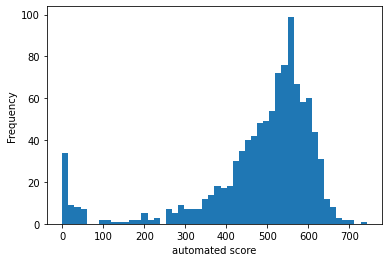

LWH10


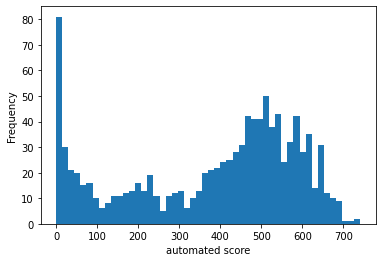

LWH25


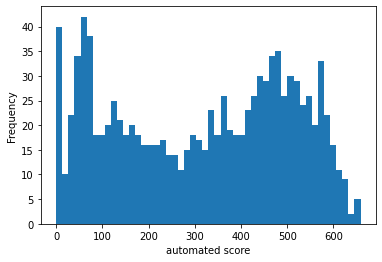

LWA


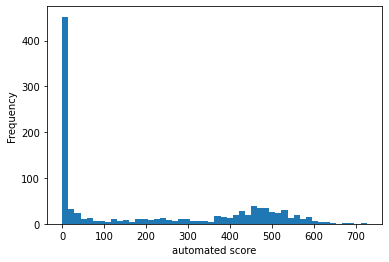

In [ ]:
for condition in ['LWH1', 'LWH10', 'LWH25', 'LWA']:
    print(condition)
    auto_df_ppi_filtered_wt.to_pandas()[auto_df_ppi_filtered_wt.to_pandas().condition_name == condition].per_well_integrated_intensity_gray.plot.hist(bins=50)
    plt.xlabel(f'automated score')
    plt.show()

In [ ]:
auto_df_ppi_filtered_alleles = auto_df_ppi_filtered.filter(
    (pl.col("db_mut_id") != 0.0))

LWH1


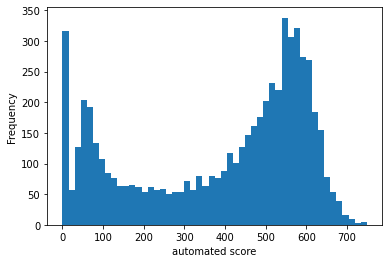

LWH10


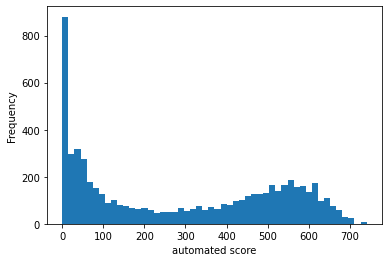

LWH25


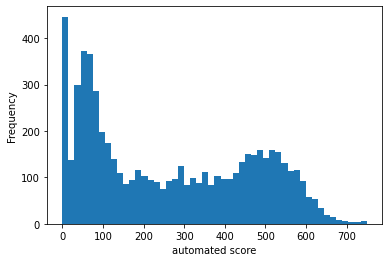

LWA


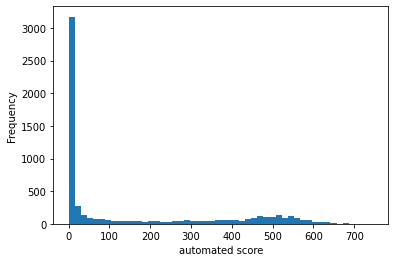

In [ ]:
for condition in ['LWH1', 'LWH10', 'LWH25', 'LWA']:
    print(condition)
    auto_df_ppi_filtered_alleles.to_pandas()[auto_df_ppi_filtered_alleles.to_pandas().condition_name == condition].per_well_integrated_intensity_gray.plot.hist(bins=50)
    plt.xlabel(f'automated score')
    plt.show()

Number of WT replicate comparisons: 1421
Mean absolute log2 FC between WT replicates: 0.341
Std of absolute log2 FC between WT replicates: 0.772


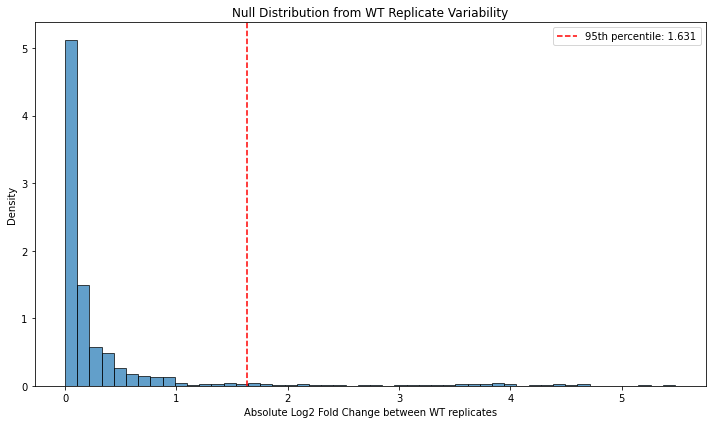


Proposed thresholds for disruption:
95th percentile of WT variability: 1.631
99th percentile of WT variability: 4.216
Mean + 2 standard deviations: 1.884
Mean + 3 standard deviations: 2.656


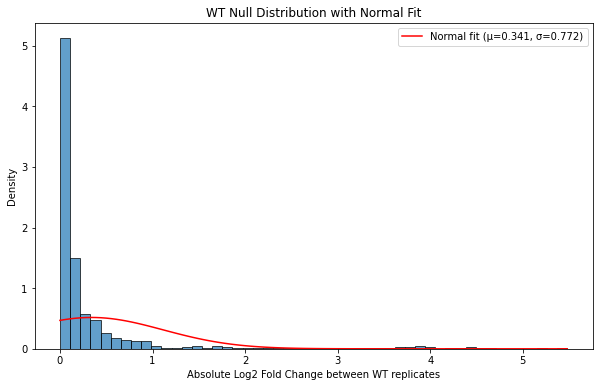


Fitted normal distribution parameters:
Mean (μ): 0.341
Standard deviation (σ): 0.772


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plot_df = auto_df_ppi_filtered_wt.filter((pl.col("per_well_integrated_intensity_gray") > 0.0) &
                                                         (pl.col("condition_name") == 'LWH1')
                                                         )

# 1. Calculate WT mean for each PPI pair across replicates
wt_means = plot_df.group_by(
    ["ad_orf_id", "db_orf_id", "condition_name", "retest_batch"]
).agg([
    pl.col("per_well_integrated_intensity_gray").mean().alias("wt_mean_score"),
    pl.col("per_well_integrated_intensity_gray").count().alias("n_replicates"),
    pl.col("per_well_integrated_intensity_gray").std().alias("wt_std_score")
]).filter(pl.col("n_replicates") >= 2)  # Only pairs with multiple WT replicates

# 2. Create null distribution from WT replicate differences
# Calculate pairwise differences between WT replicates for the same PPI pair
wt_replicate_diffs = []

for row in wt_means.iter_rows(named=True):
    # Get all WT replicates for this specific PPI pair and condition
    wt_reps = plot_df.filter(
        (pl.col("ad_orf_id") == row["ad_orf_id"]) &
        (pl.col("db_orf_id") == row["db_orf_id"]) &
        (pl.col("condition_name") == row["condition_name"]) &
        (pl.col("retest_batch") == row["retest_batch"]) &
        pl.col("per_well_integrated_intensity_gray").is_not_null()
    )["per_well_integrated_intensity_gray"].to_list()
    
    if len(wt_reps) >= 2:
        # Calculate all pairwise log2 fold changes between WT replicates
        for i in range(len(wt_reps)):
            for j in range(i+1, len(wt_reps)):
                if wt_reps[i] > 0 and wt_reps[j] > 0:  # Avoid log of negative/zero
                    log2_fc = np.log2(wt_reps[i] / wt_reps[j])
                    wt_replicate_diffs.append(abs(log2_fc))  # Take absolute value

wt_replicate_diffs = np.array(wt_replicate_diffs)

print(f"Number of WT replicate comparisons: {len(wt_replicate_diffs)}")
print(f"Mean absolute log2 FC between WT replicates: {np.mean(wt_replicate_diffs):.3f}")
print(f"Std of absolute log2 FC between WT replicates: {np.std(wt_replicate_diffs):.3f}")

# 3. Plot the null distribution
plt.figure(figsize=(10, 6))
plt.hist(wt_replicate_diffs, bins=50, alpha=0.7, density=True, edgecolor='black')
plt.xlabel('Absolute Log2 Fold Change between WT replicates')
plt.ylabel('Density')
plt.title('Null Distribution from WT Replicate Variability')

# 4. Calculate thresholds
# Method 1: Percentile-based thresholds
threshold_95 = np.percentile(wt_replicate_diffs, 95)
threshold_5 = np.percentile(wt_replicate_diffs, 5)
threshold_99 = np.percentile(wt_replicate_diffs, 99)

# Method 2: Standard deviation-based thresholds
mean_diff = np.mean(wt_replicate_diffs)
std_diff = np.std(wt_replicate_diffs)
threshold_2sd = mean_diff + 2 * std_diff
threshold_3sd = mean_diff + 3 * std_diff

# Add threshold lines to plot
plt.axvline(threshold_95, color='red', linestyle='--', 
           label=f'95th percentile: {threshold_95:.3f}')
# plt.axvline(threshold_5, color='red', linestyle='--', 
        #    label=f'5th percentile: {threshold_5:.3f}')
# plt.axvline(threshold_99, color='darkred', linestyle='--', 
#            label=f'99th percentile: {threshold_99:.3f}')
# plt.axvline(threshold_2sd, color='blue', linestyle='--', 
#            label=f'Mean + 2SD: {threshold_2sd:.3f}')
# plt.axvline(threshold_3sd, color='darkblue', linestyle='--', 
#            label=f'Mean + 3SD: {threshold_3sd:.3f}')

plt.legend()
plt.tight_layout()
plt.show()

print(f"\nProposed thresholds for disruption:")
print(f"95th percentile of WT variability: {threshold_95:.3f}")
print(f"99th percentile of WT variability: {threshold_99:.3f}")
print(f"Mean + 2 standard deviations: {threshold_2sd:.3f}")
print(f"Mean + 3 standard deviations: {threshold_3sd:.3f}")

# 5. Create a function to apply the threshold
def classify_disruption(log2_fc_abs, threshold=threshold_95):
    """Classify variants as disrupted or not based on absolute log2 fold change"""
    if pd.isna(log2_fc_abs):
        return "No data"
    elif log2_fc_abs >= threshold:
        return "Disrupted"
    else:
        return "Not disrupted"


In [ ]:
auto_df_ppi_filtered_wt

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,group_passed,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,bool,f64,f64,bool,str,str,str,str
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704.0,null,11805.0,0.0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,false,9.174929,558.350679,true,"""11805_0""","""11805_0_LW_VUSAPWT1B1""","""71704_11805_0_VUSAPWT1B1""","""71704_11805_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A16""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704.0,null,11805.0,0.0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,595.377806,false,9.334,558.350679,true,"""11805_0""","""11805_0_LW_VUSAPWT1B1""","""71704_11805_0_VUSAPWT1B1""","""71704_11805_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662.0,null,70497.0,0.0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,false,9.311877,586.988591,true,"""70497_0""","""70497_0_LW_VUSAPWT1B1""","""13662_70497_0_VUSAPWT1B1""","""13662_70497_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A18""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662.0,null,70497.0,0.0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,603.194803,false,9.35137,586.988591,true,"""70497_0""","""70497_0_LW_VUSAPWT1B1""","""13662_70497_0_VUSAPWT1B1""","""13662_70497_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567.0,null,52920.0,0.0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,false,9.281086,578.211793,true,"""52920_0""","""52920_0_LW_VUSAPWT1B1""","""11567_52920_0_VUSAPWT1B1""","""11567_52920_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT6B1r06_021""","""P12""","""VUSAPWT6B1r06_019_020_021_022_…","""VUSAPWT6B1""","""r18""","""LWAH1""","""6""",false,1172.0,null,4062.0,0.0,"""DisWTY8Dh03""","""E06""","""CEGSint_Y8A6_1""","""E09""",3.0,463.342501,false,9.003778,525.584989,true,"""4062_0""","""4062_0_LWAH1_VUSAPWT6B1""","""1172_4062_0_VUSAPWT6B1""","""1172_4062_VUSAPWT6B1"""
"""VUSAPWT6B1r06_025""","""M03""","""VUSAPWT6B1r06_025_026_027_xxx_…","""VUSAPWT6B1""","""r18""","""LWAH1""","""6""",false,14387.0,null,7652.0,0.0,"""DisWTY8Dh03""","""F03""","""CEGSint_Y8A6_2""","""A04""",3.0,439.415703,false,8.934917,465.969953,true,"""7652_0""","""7652_0_LWAH1_VUSAPWT6B1""","""14387_7652_0_VUSAPWT6B1""","""14387_7652_VUSAPWT6B1"""
"""VUSAPWT6B1r06_025""","""M04""","""VUSAPWT6B1r06_025_026_027_xxx_…","""VUSAPWT6B1""","""r18""","""LWAH1""","""6""",false,14387.0,null,7652.0,0.0,"""DisWTY8Dh03""","""F03""","""CEGSint_Y8A6_2""","""A04""",3.0,507.552961,false,9.122965,465.969953,true,"""7652_0""","""7652_0_LWAH1_VUSAPWT6B1""","""14387_7652_0_VUSAPWT6B1""","""14387_7652_VUSAPWT6B1"""


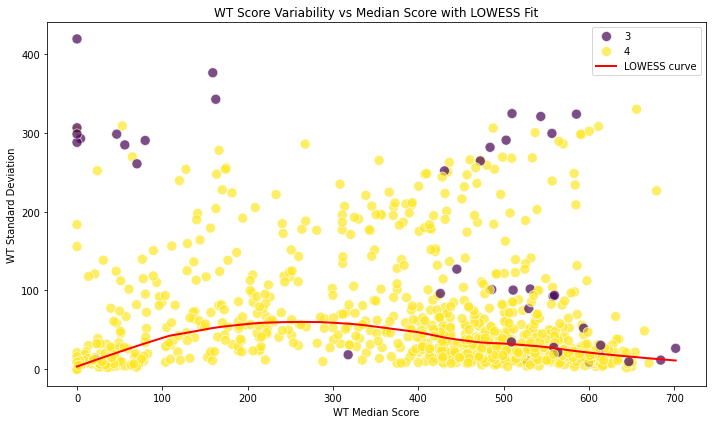

LOWESS curve covers median range: 0.0 to 701.8
LOWESS curve covers std range: 3.5 to 60.1


In [ ]:
plot_df = auto_df_ppi_filtered_wt.filter((pl.col("consensus_score").is_not_null()) &
                                         (pl.col("condition_name").is_in(['LWH1', 'LWH10', 'LWH25', 'LWA']))
)

wt_means = plot_df.group_by(
    ["ad_orf_id", "db_orf_id", "condition_name", "retest_batch"]
).agg([
    pl.col("per_well_integrated_intensity_gray").mean().alias("wt_mean_score"),
    pl.col("per_well_integrated_intensity_gray").median().alias("wt_median_score"),
    pl.col("per_well_integrated_intensity_gray").count().alias("n_replicates"),
    pl.col("per_well_integrated_intensity_gray").std().alias("wt_std_score")
]).filter(pl.col("n_replicates") >= 2)  # Only pairs with multiple WT replicates

# Convert to pandas for easier manipulation
wt_means_pd = wt_means.to_pandas()

# Remove any NaN values for LOWESS fitting
clean_data = wt_means_pd.dropna(subset=['wt_median_score', 'wt_std_score'])

# Fit LOWESS curve
from statsmodels.nonparametric.smoothers_lowess import lowess

# Fit LOWESS (frac controls the smoothness - smaller = less smooth, larger = more smooth)
lowess_result = lowess(clean_data['wt_std_score'], clean_data['wt_median_score'], frac=0.3)

# Extract the fitted values
x_smooth = lowess_result[:, 0]
y_smooth = lowess_result[:, 1]

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=wt_means_pd, x="wt_median_score", y="wt_std_score", hue="n_replicates", palette="viridis", s=100, alpha=0.7)

# Add LOWESS curve
plt.plot(x_smooth, y_smooth, color='red', linewidth=2, label='LOWESS curve')

plt.xlabel('WT Median Score')
plt.ylabel('WT Standard Deviation')
plt.title('WT Score Variability vs Median Score with LOWESS Fit')
plt.legend()
plt.tight_layout()
plt.show()

# Print some statistics about the fit
print(f"LOWESS curve covers median range: {x_smooth.min():.1f} to {x_smooth.max():.1f}")
print(f"LOWESS curve covers std range: {y_smooth.min():.1f} to {y_smooth.max():.1f}")

In [ ]:
wt_means

ad_orf_id,db_orf_id,condition_name,retest_batch,wt_mean_score,wt_median_score,n_replicates,wt_std_score
f64,f64,str,str,f64,f64,u32,f64
1769.0,3535.0,"""LWH25""","""VUSAPWT1B1""",351.682356,354.444448,4,13.727094
4973.0,70368.0,"""LWA""","""VUSAPWT1B2""",0.0,0.0,4,0.0
71163.0,52920.0,"""LWH10""","""VUSAPWT2B1""",241.785956,221.271249,4,83.637694
10064.0,52920.0,"""LWH1""","""VUSAPWT2B1""",451.626816,525.783681,4,188.810358
14387.0,7652.0,"""LWH10""","""VUSAPWT6B1""",506.732045,524.841849,4,127.035959
…,…,…,…,…,…,…,…
2794.0,13796.0,"""LWH10""","""VUSAPWT2B1""",188.992817,53.077125,4,308.808531
10352.0,71191.0,"""LWH25""","""VUSAPWT1B2""",48.713073,49.955556,4,5.389197
2920.0,2920.0,"""LWH25""","""VUSAPWT1B2""",183.975822,174.073861,4,36.710535


In [ ]:
auto_df_ppi_filtered_wt.filter((pl.col("ad_orf_id") == 2794.0) &
                               (pl.col("db_orf_id") == 13796.0) &
                               (pl.col("condition_name") == 'LWH10') 
                               )

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,group_passed,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,bool,f64,f64,bool,str,str,str,str
"""VUSAPWT2B1r04_018""","""I13""","""VUSAPWT2B1r04_013_014_015_016_…","""VUSAPWT2B1""","""r16""","""LWH10""","""2""",false,2794.0,null,13796.0,0.0,"""DisWTY8Dh03""","""C06""","""CEGSint_Y8A2_2""","""D08""",3.0,76.150328,false,6.979,188.992817,true,"""13796_0""","""13796_0_LWH10_VUSAPWT2B1""","""2794_13796_0_VUSAPWT2B1""","""2794_13796_VUSAPWT2B1"""
"""VUSAPWT2B1r04_018""","""I14""","""VUSAPWT2B1r04_013_014_015_016_…","""VUSAPWT2B1""","""r16""","""LWH10""","""2""",false,2794.0,null,13796.0,0.0,"""DisWTY8Dh03""","""C06""","""CEGSint_Y8A2_2""","""D08""",3.0,0.0,false,5.643856,188.992817,true,"""13796_0""","""13796_0_LWH10_VUSAPWT2B1""","""2794_13796_0_VUSAPWT2B1""","""2794_13796_VUSAPWT2B1"""
"""VUSAPWT2B1r04_018""","""J13""","""VUSAPWT2B1r04_013_014_015_016_…","""VUSAPWT2B1""","""r16""","""LWH10""","""2""",false,2794.0,null,13796.0,0.0,"""DisWTY8Dh03""","""C06""","""CEGSint_Y8A2_2""","""D08""",3.0,30.003922,false,6.321999,188.992817,true,"""13796_0""","""13796_0_LWH10_VUSAPWT2B1""","""2794_13796_0_VUSAPWT2B1""","""2794_13796_VUSAPWT2B1"""
"""VUSAPWT2B1r04_018""","""J14""","""VUSAPWT2B1r04_013_014_015_016_…","""VUSAPWT2B1""","""r16""","""LWH10""","""2""",false,2794.0,null,13796.0,0.0,"""DisWTY8Dh03""","""C06""","""CEGSint_Y8A2_2""","""D08""",3.0,649.817018,false,9.450834,188.992817,true,"""13796_0""","""13796_0_LWH10_VUSAPWT2B1""","""2794_13796_0_VUSAPWT2B1""","""2794_13796_VUSAPWT2B1"""
